# 🚗 Bangla License Plate Recognition with YOLO

**Table of Contents**

1. **Introduction & Setup**
   - 1.1 Install Ultralytics & check the GPU
   - 1.2 Mount Google Drive
   - 1.3 Download the dataset
   - 1.4 Understanding the YOLO dataset format
   - 1.5 Fix the dataset config (`data.yaml`)
   - 1.6 Visualization helper functions
   - 1.7 Measuring performance: IoU, Precision/Recall, AP, mAP
   - 1.8 YOLO model training process using ultrlytics library
2. **Vehicle → License Plate Detection**
   - 2.1 Check out the dataset config
   - 2.2 Example images with labels
   - 2.3 Train the plate detector
   - 2.4 Evaluate on the test set
   - 2.5 Inference
3. **License Plate → Text Recognition**
   - 3.1 Check out the dataset config
   - 3.2 Example images with labels
   - 3.3 Train the character detector
   - 3.4 Evaluate on the test set
   - 3.5 Inference
4. **End-to-End Pipeline: Image → Plate Text**
   - 4.1 The `read_plates()` function
   - 4.2 Run on test images
   - 4.3 Step-by-step visualization with real images
   - 4.4 Results grid
5. **Improving Object Detection Accuracy**
6. **Exporting Models: ONNX and TensorRT**
7. **Bonus: Build your own dataset with Roboflow**

> **Runtime:** use a GPU (`Runtime → Change runtime type → T4 GPU`).

# 1. Introduction & Setup

In this notebook we build a complete **Automatic Number Plate Recognition (ANPR)** system for Bangladeshi vehicles using two YOLO object detectors:

- **Model 1: Plate detector.** It finds the license plate in a photo of a vehicle.
- **Model 2: Character detector.** It finds each character or word on the cropped plate.

Then we combine them into a **pipeline** that takes an image and returns the plate text, for example `ঢাকা মেট্রো গ / ১১-২৩৪৫`.

In [ ]:
# @title
%%html
<style>
.lp{font-family:system-ui,-apple-system,sans-serif;background:#ffffff;color:#1f2937;padding:20px 24px;border-radius:12px;border:1px solid #e5e7eb;max-width:960px;line-height:1.55}
.lp h3{margin:0 0 4px;color:#111827}
.lp .sub{color:#6b7280;margin:0 0 16px;font-size:14px}
.lp .flow{display:flex;align-items:stretch;gap:6px;flex-wrap:wrap}
.lp .box{border-radius:10px;padding:10px 12px;text-align:center;font-size:13px;flex:1;min-width:110px;display:flex;flex-direction:column;justify-content:center}
.lp .data{background:#eef2ff;border:1px solid #c7d2fe}
.lp .model{background:#fef3c7;border:1px solid #f59e0b;font-weight:600}
.lp .logic{background:#ecfeff;border:1px solid #67e8f9;font-weight:600}
.lp .out{background:#dcfce7;border:1px solid #22c55e;font-weight:600;font-size:15px}
.lp .arrow{align-self:center;font-size:22px;color:#9ca3af}
.lp .big{font-size:26px;margin-bottom:4px}
.lp small{color:#6b7280;font-weight:400}
.lp .legend{margin-top:14px;font-size:13px;color:#4b5563}
.lp .legend span{display:inline-block;width:12px;height:12px;border-radius:3px;vertical-align:middle;margin:0 4px 0 12px}
</style>
<div class="lp">
  <h3>The two-stage ANPR system we will build</h3>
  <p class="sub">Each model solves one easy problem. Chaining them solves the hard one.</p>
  <div class="flow">
    <div class="box data"><div class="big">🚙</div>Vehicle photo<br><small>any size</small></div>
    <div class="arrow">➜</div>
    <div class="box model"><div class="big">🔍</div>Model 1<br><small>YOLO plate detector<br>1 class</small></div>
    <div class="arrow">➜</div>
    <div class="box data"><div class="big">▭</div>Plate crop<br><small>cut out of the photo</small></div>
    <div class="arrow">➜</div>
    <div class="box model"><div class="big">🔤</div>Model 2<br><small>YOLO character detector<br>102 classes</small></div>
    <div class="arrow">➜</div>
    <div class="box logic"><div class="big">↕↔</div>Sort boxes<br><small>into lines, left→right</small></div>
    <div class="arrow">➜</div>
    <div class="box out">ঢাকা মেট্রো গ<br>১১-২৩৪৫</div>
  </div>
  <div class="legend">
    <span style="background:#eef2ff;border:1px solid #c7d2fe"></span>data
    <span style="background:#fef3c7;border:1px solid #f59e0b"></span>trained YOLO model
    <span style="background:#ecfeff;border:1px solid #67e8f9"></span>plain Python logic
    <span style="background:#dcfce7;border:1px solid #22c55e"></span>final output
  </div>
</div>

### 1.1 Install Ultralytics & check the GPU

Install the [Ultralytics](https://docs.ultralytics.com) library, which provides YOLO training and inference, then confirm that a GPU is available.

In [ ]:
!pip install -q ultralytics
import ultralytics
ultralytics.checks()

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.6/112.6 GB disk)


In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv || echo "NO GPU"

name, memory.total [MiB]
Tesla T4, 15360 MiB


### 1.2 Mount Google Drive

Colab VMs are **temporary**. If the session disconnects, everything in `/content` is gone. We tell YOLO to write its training runs (weights, plots, metrics) directly to Google Drive, so the trained models survive.

Each training run creates:
- `weights/best.pt`: the epoch with the best validation mAP. **This is the one we use.**
- `weights/last.pt`: the final epoch, used to resume training.
- `results.csv` / `results.png`: loss and metric curves per epoch.
- `confusion_matrix.png`, `BoxPR_curve.png`, `val_batch*_pred.jpg`: evaluation plots.

In [ ]:
# Mount Google Drive so trained weights survive a Colab disconnect
import os
from google.colab import drive
drive.mount("/content/drive")
RUNS_DIR = "/content/drive/MyDrive/yolo_license_plate/runs"
os.makedirs(RUNS_DIR, exist_ok=True)
print("Training outputs will be saved to", RUNS_DIR)

Mounted at /content/drive
Training outputs will be saved to /content/drive/MyDrive/yolo_license_plate/runs


### 1.3 Download the dataset

We use the [Bangla License Plate dataset](https://www.kaggle.com/datasets/arstrxshad/banglabengali-license-plate-with-number-detection) from Kaggle, a YOLO-ready version of *Bangla LPDB-A* (Sams & Shomee, 2021). `kagglehub` downloads and caches it for us.

It contains **two datasets**, one for each model:

| Folder | Task | Classes | Train / Val / Test |
|---|---|---|---|
| `Vehicle_to_License_Plate` | find the plate in a vehicle photo | 1 | 1350 / 385 / 194 |
| `License_Plate_to_Text` | find each character on a plate | 102 | 1865 / 533 / 267 |

In [ ]:
import kagglehub, os
path = kagglehub.dataset_download("arstrxshad/banglabengali-license-plate-with-number-detection")
print(path)
for root, dirs, files in os.walk(path):
    depth = root[len(path):].count(os.sep)
    if depth <= 3:
        print("  " * depth + os.path.basename(root) + f"/  ({len(files)} files)")

Using Colab cache for faster access to the 'banglabengali-license-plate-with-number-detection' dataset.
/kaggle/input/banglabengali-license-plate-with-number-detection
banglabengali-license-plate-with-number-detection/  (3 files)
  Vehicle_to_License_Plate/  (1 files)
    val/  (0 files)
      labels/  (385 files)
      images/  (385 files)
    test/  (0 files)
      labels/  (194 files)
      images/  (194 files)
    train/  (0 files)
      labels/  (1350 files)
      images/  (1350 files)
  License_Plate_to_Text/  (3 files)
    val/  (1 files)
      labels/  (533 files)
      images/  (533 files)
    test/  (0 files)
      labels/  (267 files)
      images/  (267 files)
    train/  (1 files)
      labels/  (1865 files)
      images/  (1865 files)


In [ ]:
DATASET_PATH = path

In [ ]:
# @title
import os
import glob
from IPython.display import display, Markdown

files = sorted(glob.glob(path + "/**/*", recursive=True))

files = [
    f for f in files
    if os.path.isfile(f)
    and "/images/" not in f
    and "/labels/" not in f
]

# 1. Display all YAML files first
for f in files:
    if f.endswith((".yaml", ".yml")):
        print(f"\n{'=' * 80}")
        print(f"YAML: {f.replace(path, '')}")
        print("=" * 80)

        with open(f, "r", encoding="utf-8") as file:
            print(file.read())

# 2. Display all Markdown files afterward
for f in files:
    if f.endswith(".md"):
        print(f"\n{'=' * 80}")
        print(f"MARKDOWN: {f.replace(path, '')}")
        print("=" * 80)

        with open(f, "r", encoding="utf-8") as file:
            display(Markdown(file.read()))


YAML: /License_Plate_to_Text/data-bn.yaml
train: ../train/images
val: ../val/images
test: ../test/images

nc: 102
names : [
    "0", "১", "২", "৩", "৪", "৫", "৬", "৭", "৮", "৯", "মেট্রো",
    "অ", "ভ", "চ", "ছ", "ড", "দ", "এ", "গ", "ঘ", "হ", "জ", "ঝ",
    "ক", "খ", "ল", "ম", "ন", "প", "স", "শ", "ট", "ঠ", "থ", "উ",
    "বাগেরহাট", "বগুড়া", "বান্দরবান", "বাগেরহাট", "বরিশাল", "ভোলা",
    "ব্রাহ্মণবাড়িয়া", "চাঁদপুর", "চাপাইনবাবগঞ্জ", "চট্ট", "চট্টগ্রাম",
    "চুয়াডাঙ্গা", "কক্সবাজার", "কুমিল্লা", "ঢাকা", "দিনাজপুর", "ফরিদপুর",
    "ফেনী", "গাইবান্ধা", "গাজীপুর", "গোপালগঞ্জ", "হবিগঞ্জ", "জামালপুর",
    "যশোর", "ঝালকাঠি", "ঝিনাইদহ", "জয়পুরহাট", "খাগড়াছড়ি", "খুলনা",
    "কিশোরগঞ্জ", "কুড়িগ্রাম", "কুষ্টিয়া", "লক্ষ্মীপুর", "লালমনিরহাট",
    "মাদারিপুর", "মাগুরা", "মানিকগঞ্জ", "মেহেরপুর", "মৌলভীবাজার",
    "ময়মনসিংহ", "নওগাঁ", "নারাইল", "নারায়ণগঞ্জ", "নরসিংদী", "নাটোর",
    "নেত্রকোণা", "নীলফামারি", "নোয়াখালী", "পাবনা", "পঞ্চগড়", "পটুয়াখালি",
    "পিরোজপুর", "রাজ", "রাজবাড়ী", "রা

# Bangla LPDB - A (YOLO Ready)

This dataset is a reformatted and enhanced version of the **Bangla LPDB - A** dataset, originally published by Ataher Sams and Homaira Huda Shomee. It has been meticulously prepared to be **plug-and-play** for YOLO (You Only Look Once) object detection models, making it incredibly easy for researchers and developers to use for license plate detection tasks in Bangladeshi vehicles.

---

## Original Dataset Acknowledgment

This dataset is built upon 

Ataher Sams, & Homaira Huda Shomee. (2021). Bangla LPDB - A (Version v1) [Data set]. International Conference on Digital Image Computing: Techniques and Applications (IEEE DICTA), Gold Coast, Queensland Australia. Zenodo. https://doi.org/10.5281/zenodo.4718238

We extend our sincerest gratitude to them for creating such a comprehensive and vital resource for the research community.

---

## Key Enhancements

While the original Bangla LPDB - A dataset is an excellent collection, this version provides significant improvements for immediate use with YOLO models:

* **YOLO Dataset Structure:** The dataset has been meticulously restructured to follow the standard YOLO format, including all necessary annotation files.
* **`dataset.yaml` Included:** A `dataset.yaml` file is provided for seamless integration with popular deep learning frameworks like Ultralytics YOLO.
* **Class Names:** Separate files for both **Bengali** and **English** class names are included, offering flexibility for various applications.
* **Pre-split Data:** The dataset is pre-split into optimal ratios for training, validation, and testing:
  * **Training Set:** 70%
  * **Validation Set:** 20%
  * **Testing Set:** 10%
  * 

---

## Preview

License Plate to Text

![](./license-plate-to-text.png)

Vehicle to License Plat

![](./vehicle-to-license-plate.png)

---

## The Original Paper

H. H. Shomee and A. Sams, "License Plate Detection and Recognition System for All Types of Bangladeshi Vehicles Using Multi-step Deep Learning Model," 2021 Digital Image Computing: Techniques and Applications (DICTA), Gold Coast, Australia, 2021, pp. 01-07,  https://doi.org/10.1109/DICTA52665.2021.9647284.

---

## Dataset Citation

**Users of this dataset are required to cite the original research paper**, which introduces the Bangla LPDB - A dataset and its applications. Please use the following citation:

```bibtex
@INPROCEEDINGS{9647284,
  author={Shomee, H. H. and Sams, A.},
  booktitle={2021 Digital Image Computing: Techniques and Applications (DICTA)},
  title={License Plate Detection and Recognition System for All Types of Bangladeshi Vehicles Using Multi-step Deep Learning Model},
  year={2021},
  pages={01-07},
  doi={10.1109/DICTA52665.2021.9647284}
}
```

---

> Modified by
> 
> **Ashikur Rahman Shad**
> 
> [ashikur-rahman-shad (Ashikur Rahman Shad) · GitHub](https://github.com/ashikur-rahman-shad/)
> 
> 


### 1.4 Understanding the YOLO dataset format

Before training, students should understand **how YOLO expects the data to be laid out**. The diagram below explains the folder structure, the label file format, and the `data.yaml` config. The code cell after it reads real label files and draws their boxes.

In [ ]:
# @title
%%html
<style>
.lp{font-family:system-ui,-apple-system,sans-serif;background:#ffffff;color:#1f2937;padding:20px 24px;border-radius:12px;border:1px solid #e5e7eb;max-width:960px;line-height:1.55}
.lp h3{margin:18px 0 8px;color:#111827}.lp h3:first-child{margin-top:0}
.lp .grid{display:grid;grid-template-columns:1fr 1fr;gap:20px}
@media (max-width:700px){.lp .grid{grid-template-columns:1fr}}
.lp pre{background:#0f172a;color:#e2e8f0;padding:12px 14px;border-radius:8px;font-size:13px;line-height:1.5;margin:0;overflow-x:auto}
.lp .c{color:#94a3b8}.lp .k{color:#fbbf24}.lp .g{color:#86efac}
.lp code{background:#f3f4f6;padding:1px 5px;border-radius:4px;font-size:13px}
.lp .line{font-family:ui-monospace,monospace;font-size:20px;display:flex;gap:10px;flex-wrap:wrap;margin:6px 0}
.lp .tok{text-align:center;padding:6px 10px;border-radius:8px}
.lp .tok small{display:block;font-family:system-ui;font-size:11px;color:#374151;margin-top:2px}
.lp .note{background:#f0fdf4;border-left:4px solid #22c55e;padding:8px 12px;margin-top:14px;font-size:14px}
.lp .warn{background:#fff7ed;border-left:4px solid #f97316;padding:8px 12px;margin-top:10px;font-size:14px}
</style>
<div class="lp">
  <div class="grid">
    <div>
      <h3>① Folder structure</h3>
<pre>Vehicle_to_License_Plate/
├── <span class="k">data.yaml</span>          <span class="c"># dataset config</span>
├── train/
│   ├── images/
│   │   ├── <span class="g">car001.jpg</span>
│   │   └── car002.jpg
│   └── labels/
│       ├── <span class="g">car001.txt</span>     <span class="c"># same name!</span>
│       └── car002.txt
├── val/    <span class="c"># images/ + labels/</span>
└── test/   <span class="c"># images/ + labels/</span></pre>
      <p style="font-size:14px">Every image has a <b>.txt label file with the same name</b>. YOLO finds the labels by replacing <code>/images/</code> with <code>/labels/</code> in the path.</p>
    </div>
    <div>
      <h3>② The <code>data.yaml</code> config</h3>
<pre><span class="k">path</span>: /content/.../Vehicle_to_License_Plate  <span class="c"># root</span>
<span class="k">train</span>: train/images   <span class="c"># relative to path</span>
<span class="k">val</span>:   val/images
<span class="k">test</span>:  test/images
<span class="k">nc</span>: 1                 <span class="c"># number of classes</span>
<span class="k">names</span>:
  - License Plate     <span class="c"># class id 0</span></pre>
      <p style="font-size:14px"><b>Train</b> is what the model learns from. <b>Val</b> is checked after every epoch to pick the best weights. <b>Test</b> is never seen during training and gives an honest final score.</p>
    </div>
  </div>

  <h3>③ One line in a label file = one object</h3>
  <div class="line">
    <div class="tok" style="background:#fde68a">0<small>class id</small></div>
    <div class="tok" style="background:#bfdbfe">0.550<small>x_center</small></div>
    <div class="tok" style="background:#bfdbfe">0.620<small>y_center</small></div>
    <div class="tok" style="background:#bbf7d0">0.300<small>width</small></div>
    <div class="tok" style="background:#bbf7d0">0.180<small>height</small></div>
  </div>
  <div class="grid" style="align-items:center">
    <svg viewBox="0 0 420 280" style="width:100%;max-width:440px">
      <rect x="10" y="10" width="400" height="260" fill="#f1f5f9" stroke="#64748b" stroke-width="2"/>
      <text x="16" y="28" font-size="12" fill="#475569">(0,0)</text>
      <text x="360" y="264" font-size="12" fill="#475569">(1,1)</text>
      <rect x="170" y="148.6" width="120" height="46.8" fill="rgba(250,204,21,.25)" stroke="#ca8a04" stroke-width="3"/>
      <circle cx="230" cy="172" r="5" fill="#2563eb"/>
      <line x1="10" y1="172" x2="225" y2="172" stroke="#2563eb" stroke-dasharray="5 4"/>
      <line x1="230" y1="10" x2="230" y2="167" stroke="#2563eb" stroke-dasharray="5 4"/>
      <text x="236" y="40" font-size="13" fill="#1d4ed8">x_center = 0.55</text>
      <text x="16" y="166" font-size="13" fill="#1d4ed8">y_center = 0.62</text>
      <line x1="170" y1="212" x2="290" y2="212" stroke="#16a34a" stroke-width="2"/>
      <text x="196" y="230" font-size="13" fill="#15803d">width = 0.30</text>
      <line x1="305" y1="148.6" x2="305" y2="195.4" stroke="#16a34a" stroke-width="2"/>
      <text x="312" y="176" font-size="13" fill="#15803d">height = 0.18</text>
    </svg>
    <div style="font-size:14px">
      <p>All four numbers are <b>normalized to 0–1</b>, divided by the image width or height. The same label works at any image resolution.</p>
      <p>Converting back to pixel corners for an image of size <code>W×H</code>:</p>
<pre>x1 = (x_center - width/2)  * W
y1 = (y_center - height/2) * H
x2 = (x_center + width/2)  * W
y2 = (y_center + height/2) * H</pre>
    </div>
  </div>
  <div class="note">💡 An image with <b>no objects</b> gets an <b>empty</b> .txt file (a "background" image). These help the model learn what <i>not</i> to detect.</div>
  <div class="warn">⚠️ Class ids must be in <code>0 … nc-1</code>, and every value must be in <code>[0, 1]</code>. In Section 1.5 we check this for our data.</div>
</div>

### 1.5 Fix the dataset config (`data.yaml`)

The `data.yaml` files that ship with the dataset use paths like `train: ../train/images` and have no `path:` root. We write our own clean copies with an **explicit absolute root**. We also run a few **sanity checks** on the labels before spending GPU time on training.

In [ ]:
# @title
%%html
<style>
.lp{font-family:system-ui,-apple-system,sans-serif;background:#ffffff;color:#1f2937;padding:20px 24px;border-radius:12px;border:1px solid #e5e7eb;max-width:960px;line-height:1.55}
.lp h3{margin:0 0 10px;color:#111827}
.lp .grid{display:grid;grid-template-columns:1fr auto 1fr;gap:14px;align-items:center}
@media (max-width:700px){.lp .grid{grid-template-columns:1fr}}
.lp pre{background:#0f172a;color:#e2e8f0;padding:12px 14px;border-radius:8px;font-size:13px;margin:0;overflow-x:auto}
.lp .bad{color:#fca5a5}.lp .good{color:#86efac}.lp .c{color:#94a3b8}
.lp .label{font-size:12px;font-weight:700;text-transform:uppercase;letter-spacing:.05em;margin-bottom:6px}
.lp ul{font-size:14px;margin:12px 0 0;padding-left:20px}
.lp code{background:#f3f4f6;padding:1px 5px;border-radius:4px;font-size:13px}
</style>
<div class="lp">
  <h3>Original vs fixed <code>data.yaml</code></h3>
  <div class="grid">
    <div>
      <div class="label" style="color:#dc2626">Original (shipped with dataset)</div>
<pre><span class="c"># no "path:" key</span>
train: <span class="bad">../train/images</span>
val:   <span class="bad">../val/images</span>
test:  <span class="bad">../test/images</span>
nc: 102
names : [...]</pre>
    </div>
    <div style="font-size:28px;color:#9ca3af;text-align:center">➜</div>
    <div>
      <div class="label" style="color:#16a34a">Fixed (written by us)</div>
<pre><span class="good">path: /root/.cache/kagglehub/.../License_Plate_to_Text</span>
train: <span class="good">train/images</span>
val:   <span class="good">val/images</span>
test:  <span class="good">test/images</span>
nc: 102
names: [...]</pre>
    </div>
  </div>
  <ul>
    <li><code>../train/images</code> means "go <b>up</b> one folder from the yaml". Taken literally, that points <i>outside</i> the dataset. Ultralytics has a fallback that strips a leading <code>../</code> when the path doesn't exist, so it may still load. Relying on a hidden fallback is fragile, though.</li>
    <li>With an explicit <code>path:</code> root, every split is simply <code>root + train/images</code>. It's easy to read and works wherever the yaml file lives.</li>
    <li>Sanity checks: <code>len(names) == nc</code>, every class id &lt; <code>nc</code>, and every class actually appears in the labels.</li>
  </ul>
</div>

In [ ]:
# Fix dataset yamls: absolute `path` + relative splits (originals use ../train/images, which resolves outside the dataset)
import yaml, os, glob, kagglehub
from collections import Counter
from PIL import Image

path = kagglehub.dataset_download("arstrxshad/banglabengali-license-plate-with-number-detection")
os.makedirs("/content/yolo_data", exist_ok=True)

def fix(sub, out):
    d = os.path.join(path, sub)
    cfg = yaml.safe_load(open(os.path.join(d, "data.yaml")))
    new = {"path": d, "train": "train/images", "val": "val/images", "test": "test/images",
           "nc": cfg["nc"], "names": cfg["names"]}
    assert len(new["names"]) == new["nc"], (sub, len(new["names"]), new["nc"])
    yaml.safe_dump(new, open(out, "w"), allow_unicode=True, sort_keys=False)
    # sanity: label class ids in range, image sizes
    ids, sizes = Counter(), []
    for lf in glob.glob(f"{d}/*/labels/*.txt"):
        for line in open(lf):
            if line.strip():
                ids[int(line.split()[0])] += 1
    for im in sorted(glob.glob(f"{d}/train/images/*"))[:200]:
        sizes.append(Image.open(im).size)
    ws, hs = sorted(s[0] for s in sizes), sorted(s[1] for s in sizes)
    print(f"{sub}: nc={new['nc']} max_id={max(ids)} boxes={sum(ids.values())} "
          f"median img {ws[len(ws)//2]}x{hs[len(hs)//2]}  unused classes={new['nc']-len(ids)}")
    return out

PLATE_YAML = fix("Vehicle_to_License_Plate", "/content/yolo_data/plate.yaml")
TEXT_YAML = fix("License_Plate_to_Text", "/content/yolo_data/text.yaml")
print(open(PLATE_YAML).read())

Using Colab cache for faster access to the 'banglabengali-license-plate-with-number-detection' dataset.
Vehicle_to_License_Plate: nc=1 max_id=0 boxes=1986 median img 640x640  unused classes=0
License_Plate_to_Text: nc=102 max_id=101 boxes=22168 median img 557x370  unused classes=0
path: /kaggle/input/banglabengali-license-plate-with-number-detection/Vehicle_to_License_Plate
train: train/images
val: val/images
test: test/images
nc: 1
names:
- License Plate



In [ ]:
from ultralytics.data.utils import check_det_dataset
for y in [PLATE_YAML, TEXT_YAML]:
    d = check_det_dataset(y)
    print(y, "->", d["train"], os.path.isdir(d["train"]), "| val ok:", os.path.isdir(d["val"]))

/content/yolo_data/plate.yaml -> /kaggle/input/banglabengali-license-plate-with-number-detection/Vehicle_to_License_Plate/train/images True | val ok: True
/content/yolo_data/text.yaml -> /kaggle/input/banglabengali-license-plate-with-number-detection/License_Plate_to_Text/train/images True | val ok: True


### 1.6 Visualization helper functions

Small helpers we reuse in every section:
- `label_path_for(img)` maps `.../images/x.jpg` to `.../labels/x.txt`
- `read_yolo_labels(label, names)` loads a label file as a table
- `draw_yolo_labels(img, names)` draws the ground-truth boxes on the image

In [ ]:
import os
import glob
import cv2
import yaml
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Dataset paths
plate_dir = os.path.join(path, "Vehicle_to_License_Plate")
text_dir = os.path.join(path, "License_Plate_to_Text")

# Load class names
with open(f"{plate_dir}/data.yaml") as f:
    plate_names = yaml.safe_load(f)["names"]

with open(f"{text_dir}/data.yaml") as f:
    text_names = yaml.safe_load(f)["names"]


# 1. Helper functions
def label_path_for(img_path):
    """Convert image path to corresponding YOLO label path."""
    return os.path.splitext(
        img_path.replace("/images/", "/labels/")
    )[0] + ".txt"


def read_yolo_labels(label_path, names):
    """Read YOLO labels and return a structured DataFrame."""
    columns = ["class", "x_center", "y_center", "width", "height"]

    df = pd.read_csv(label_path, sep=r"\s+", header=None, names=columns)

    df["class_name"] = df["class"].map(
        lambda cls: names[int(cls)]
    )

    return df


def draw_yolo_labels(img_path, names, color=(0, 200, 0)):
    """Draw YOLO ground-truth bounding boxes on an image."""
    img = cv2.imread(img_path)

    if img is None:
        raise FileNotFoundError(f"Could not read image: {img_path}")

    H, W = img.shape[:2]
    label_path = label_path_for(img_path)

    if not os.path.exists(label_path):
        return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    with open(label_path) as f:
        for line in f:
            if not line.strip():
                continue

            cls, xc, yc, w, h = line.split()
            cls = int(cls)
            xc, yc, w, h = map(float, (xc, yc, w, h))

            # Normalized coordinates -> pixel coordinates
            x1 = int((xc - w / 2) * W)
            y1 = int((yc - h / 2) * H)
            x2 = int((xc + w / 2) * W)
            y2 = int((yc + h / 2) * H)

            cv2.rectangle(img, (x1, y1), (x2, y2),
                          color, max(2, W // 300))

            cv2.putText(
                img,
                names[cls],
                (x1, max(15, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX,
                max(0.4, W / 1200),
                color,
                max(1, W // 600)
            )

    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

### 1.7 Measuring performance: IoU, Precision/Recall, AP, mAP

During training YOLO prints a line like this after every epoch:

```
Class   Images  Instances   Box(P      R      mAP50   mAP50-95)
  all      385        403   0.953  0.948    0.980      0.582
```

To read it, we need four ideas: **IoU → Precision & Recall → AP → mAP**.

In [ ]:
# @title
%%html
<style>
.lp{font-family:system-ui,-apple-system,sans-serif;background:#ffffff;color:#1f2937;padding:20px 24px;border-radius:12px;border:1px solid #e5e7eb;max-width:960px;line-height:1.55;font-size:14px}
.lp h3{margin:22px 0 8px;color:#111827;font-size:17px}.lp h3:first-child{margin-top:0}
.lp .step{display:inline-block;background:#111827;color:#fff;border-radius:50%;width:24px;height:24px;text-align:center;line-height:24px;font-size:13px;margin-right:6px}
.lp .grid{display:grid;grid-template-columns:1fr 1fr;gap:22px;align-items:center}
.lp .grid3{display:grid;grid-template-columns:repeat(3,1fr);gap:12px}
@media (max-width:700px){.lp .grid,.lp .grid3{grid-template-columns:1fr}}
.lp .card{border-radius:10px;padding:10px 12px;border:1px solid}
.lp .formula{font-family:Georgia,serif;font-size:17px;text-align:center;background:#f8fafc;border-radius:8px;padding:10px;margin:6px 0}
.lp code{background:#f3f4f6;padding:1px 5px;border-radius:4px;font-size:13px}
.lp table{border-collapse:collapse;width:100%;font-size:13px}
.lp td,.lp th{border:1px solid #e5e7eb;padding:6px 8px;text-align:center}
.lp th{background:#f8fafc}
.lp .note{background:#f0fdf4;border-left:4px solid #22c55e;padding:8px 12px;margin-top:14px}
</style>
<div class="lp">

  <h3><span class="step">1</span>IoU: how well does a predicted box match the true box?</h3>
  <div class="grid">
    <svg viewBox="0 0 420 170" style="width:100%">
      <g transform="translate(10,10)">
        <rect x="0" y="20" width="90" height="70" fill="rgba(34,197,94,.25)" stroke="#16a34a" stroke-width="2"/>
        <rect x="40" y="45" width="90" height="70" fill="rgba(59,130,246,.25)" stroke="#2563eb" stroke-width="2"/>
        <rect x="40" y="45" width="50" height="45" fill="#f59e0b" opacity=".8"/>
        <text x="0" y="12" font-size="12" fill="#15803d">ground truth</text>
        <text x="60" y="132" font-size="12" fill="#1d4ed8">prediction</text>
      </g>
      <text x="165" y="80" font-size="26" fill="#374151">=</text>
      <g transform="translate(200,30)">
        <rect x="20" y="0" width="50" height="45" fill="#f59e0b"/>
        <text x="80" y="28" font-size="13" fill="#374151">Intersection</text>
        <line x1="0" y1="60" x2="200" y2="60" stroke="#374151" stroke-width="2"/>
        <rect x="0" y="72" width="40" height="32" fill="rgba(34,197,94,.35)" stroke="#16a34a"/>
        <rect x="20" y="82" width="40" height="32" fill="rgba(59,130,246,.35)" stroke="#2563eb"/>
        <text x="80" y="100" font-size="13" fill="#374151">Union</text>
      </g>
    </svg>
    <div>
      <div class="formula">IoU = Area of overlap ÷ Area of union</div>
      <p><b>IoU = 1</b> means a perfect match. <b>IoU = 0</b> means no overlap. A prediction counts as <b>correct (True Positive)</b> only if its IoU with a ground-truth box is above a threshold, for example <b>0.5</b>, <i>and</i> its class is right.</p>
    </div>
  </div>

  <h3><span class="step">2</span>Precision and Recall</h3>
  <div class="grid3">
    <div class="card" style="background:#f0fdf4;border-color:#86efac"><b>TP: True Positive</b><br>predicted a plate and there is one (IoU ≥ threshold)</div>
    <div class="card" style="background:#fef2f2;border-color:#fca5a5"><b>FP: False Positive</b><br>predicted a plate, but it's wrong (no plate, or bad IoU)</div>
    <div class="card" style="background:#fffbeb;border-color:#fcd34d"><b>FN: False Negative</b><br>a real plate the model missed</div>
  </div>
  <div class="grid" style="margin-top:10px">
    <div><div class="formula">Precision = TP ÷ (TP + FP)</div><p style="text-align:center">"Of everything I predicted, how much was right?"</p></div>
    <div><div class="formula">Recall = TP ÷ (TP + FN)</div><p style="text-align:center">"Of all real objects, how many did I find?"</p></div>
  </div>
  <p>The two pull against each other through the <b>confidence threshold</b>. A high threshold gives few, very sure predictions: high precision, low recall. A low threshold finds everything along with junk: high recall, low precision.</p>

  <h3><span class="step">3</span>AP: Average Precision = area under the Precision–Recall curve</h3>
  <div class="grid">
    <svg viewBox="0 0 320 230" style="width:100%;max-width:360px">
      <g transform="translate(45,15)">
        <path d="M0,10 L60,10 L60,22 L120,22 L120,40 L170,40 L170,75 L210,75 L210,130 L240,130 L240,180 L0,180 Z" fill="rgba(99,102,241,.2)"/>
        <path d="M0,10 L60,10 L60,22 L120,22 L120,40 L170,40 L170,75 L210,75 L210,130 L240,130 L240,180" fill="none" stroke="#4f46e5" stroke-width="2.5"/>
        <line x1="0" y1="180" x2="250" y2="180" stroke="#374151"/><line x1="0" y1="0" x2="0" y2="180" stroke="#374151"/>
        <text x="95" y="208" font-size="13" fill="#374151">Recall →</text>
        <text x="-150" y="-30" font-size="13" fill="#374151" transform="rotate(-90)">Precision →</text>
        <text x="-14" y="185" font-size="11" fill="#6b7280">0</text><text x="-14" y="14" font-size="11" fill="#6b7280">1</text>
        <text x="245" y="195" font-size="11" fill="#6b7280">1</text>
        <text x="70" y="115" font-size="16" fill="#4338ca" font-weight="700">AP = area</text>
      </g>
    </svg>
    <div>
      <p>Sweep the confidence threshold from high to low and plot (recall, precision) at each step. A perfect detector stays at precision 1 all the way to recall 1, giving <b>AP = 1.0</b>.</p>
      <p>AP summarizes the whole trade-off in <b>one number per class</b>, so you don't have to pick a threshold.</p>
    </div>
  </div>

  <h3><span class="step">4</span>mAP: mean of AP over all classes (and IoU thresholds)</h3>
  <table>
    <tr><th>Metric</th><th>IoU threshold</th><th>What it rewards</th></tr>
    <tr><td><b>mAP50</b></td><td>0.50 only</td><td>Finding the object with a roughly right box</td></tr>
    <tr><td><b>mAP50-95</b></td><td>average of 0.50, 0.55, …, 0.95</td><td>Finding it <i>and</i> drawing a <b>tight, precise</b> box (stricter)</td></tr>
  </table>
  <p style="margin-top:10px">Model 2 has 102 classes, so its mAP is the AP of "0", "1", …, "Dhaka", … averaged together. A rare class with poor AP pulls the mean down.</p>
  <div class="note">📌 <b>Reading our plate detector:</b> mAP50 ≈ 0.98 but mAP50-95 ≈ 0.6. The model <b>almost always finds the plate</b>, but its boxes aren't pixel-perfect at strict IoU thresholds like 0.9. For our pipeline that's fine, because we crop with a little padding anyway.</div>
</div>

Metric,IoU threshold,What it rewards
mAP50,0.50 only,Finding the object with a roughly right box
mAP50-95,"average of 0.50, 0.55, …, 0.95","Finding it and drawing a tight, precise box (stricter)"


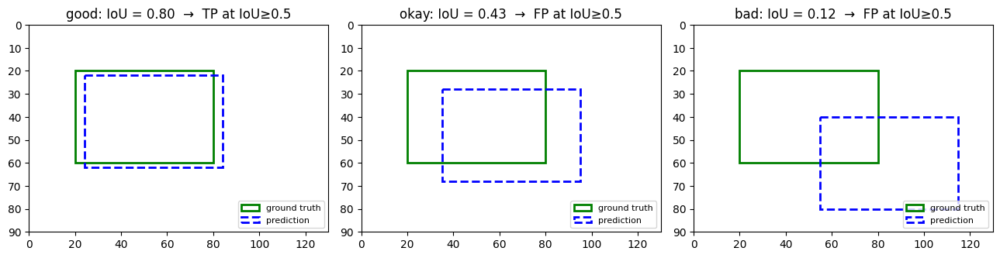

In [ ]:
# IoU in code: compute it yourself for boxes in (x1, y1, x2, y2) format
import matplotlib.patches as patches

def iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    return inter / (area_a + area_b - inter)

gt = (20, 20, 80, 60)
preds = {"good": (24, 22, 84, 62), "okay": (35, 28, 95, 68), "bad": (55, 40, 115, 80)}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (name, p) in zip(axes, preds.items()):
    v = iou(gt, p)
    ax.add_patch(patches.Rectangle(gt[:2], gt[2]-gt[0], gt[3]-gt[1], fill=False, ec="green", lw=2, label="ground truth"))
    ax.add_patch(patches.Rectangle(p[:2], p[2]-p[0], p[3]-p[1], fill=False, ec="blue", lw=2, ls="--", label="prediction"))
    ax.set_xlim(0, 130); ax.set_ylim(90, 0); ax.set_aspect("equal")
    verdict = "TP at IoU≥0.5" if v >= 0.5 else "FP at IoU≥0.5"
    ax.set_title(f"{name}: IoU = {v:.2f}  →  {verdict}")
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### 1.8 YOLO model training process using `ultrlytics` library

In [ ]:

# @title
%%html
<style>
.train-note{font-family:system-ui,-apple-system,sans-serif;background:#fff;color:#1f2937;padding:22px 24px;border-radius:12px;border:1px solid #e5e7eb;max-width:960px;line-height:1.6}
.train-note h3{color:#111827;margin:20px 0 8px}
.train-note h3:first-child{margin-top:0}
.train-note p{font-size:14px}
.train-note .code{background:#0f172a;color:#e2e8f0;padding:15px 17px;border-radius:9px;font:13px/1.7 ui-monospace,monospace;overflow-x:auto;white-space:pre}
.train-note .k{color:#fbbf24}.train-note .s{color:#86efac}.train-note .c{color:#94a3b8}.train-note .f{color:#93c5fd}
.train-note code{background:#f3f4f6;padding:2px 5px;border-radius:4px;font-size:13px}
.train-note .grid{display:grid;grid-template-columns:1fr 1fr;gap:12px;margin:12px 0}
@media(max-width:650px){.train-note .grid{grid-template-columns:1fr}}
.train-note .card{background:#f8fafc;border:1px solid #e5e7eb;border-radius:9px;padding:12px 14px}
.train-note .card b{color:#111827}
.train-note .tag{display:inline-block;background:#e0e7ff;color:#3730a3;border-radius:5px;padding:2px 7px;font-size:12px;font-weight:600}
.train-note .step{display:flex;gap:12px;align-items:flex-start;margin:12px 0}
.train-note .num{background:#e0e7ff;color:#3730a3;min-width:27px;height:27px;border-radius:50%;display:flex;align-items:center;justify-content:center;font-weight:700;font-size:13px}
.train-note .note{background:#eff6ff;border-left:4px solid #3b82f6;padding:10px 13px;margin-top:12px;font-size:14px}
.train-note .good{background:#f0fdf4;border-left:4px solid #22c55e;padding:10px 13px;margin-top:12px;font-size:14px}
.train-note .warn{background:#fff7ed;border-left:4px solid #f97316;padding:10px 13px;margin-top:12px;font-size:14px}
.train-note table{width:100%;border-collapse:collapse;font-size:13px;margin:10px 0}
.train-note th,.train-note td{text-align:left;padding:9px;border-bottom:1px solid #e5e7eb;vertical-align:top}
.train-note th{background:#f8fafc;color:#374151}
.train-note .flow{display:flex;align-items:center;justify-content:center;gap:7px;flex-wrap:wrap;margin:16px 0}
.train-note .flowbox{background:#eff6ff;border:1px solid #bfdbfe;border-radius:8px;padding:9px 12px;text-align:center;font-size:13px;font-weight:600}
.train-note .arrow{color:#64748b;font-size:20px}
</style>

<div class="train-note">

  <h3>1. Training an Object Detection Model with Ultralytics YOLO</h3>

  <p>After preparing the dataset, configuring the <code>data.yaml</code> file, and inspecting the annotations, we are ready to train an object detection model.</p>

  <p>Fortunately, Ultralytics makes this process very simple. We do not need to implement the model architecture, loss functions, backpropagation, or the training loop ourselves. The framework handles these operations internally.</p>

  <div class="good">
    <b>Key idea:</b> Load a pretrained YOLO model, provide the dataset configuration, specify the training parameters, and call <code>model.train()</code>.
  </div>

  <h3>2. The complete training code</h3>

  <div class="code"><span class="k">from</span> ultralytics <span class="k">import</span> YOLO

<span class="c"># Load a pretrained YOLO model</span>
model = YOLO(<span class="s">"yolo11s.pt"</span>)

<span class="c"># Dataset configuration file</span>
dataset_yaml_path = <span class="s">"/path/to/dataset/data.yaml"</span>

<span class="c"># Directory where training results will be saved</span>
RUNS_DIR = <span class="s">"/content/drive/MyDrive/yolo_runs"</span>

<span class="c"># Start training</span>
model.train(
    data=dataset_yaml_path,
    epochs=60,
    imgsz=640,
    batch=16,
    patience=15,
    project=RUNS_DIR,
    name=<span class="s">"object_detection"</span>,
    exist_ok=True,
)</div>

  <p>That's it! This is the actual model training code. Let's understand what each part does.</p>

  <h3>3. Understanding the training workflow</h3>

  <div class="flow">
    <div class="flowbox">Pretrained YOLO<br><small>yolo11s.pt</small></div>
    <div class="arrow">→</div>
    <div class="flowbox">Dataset<br><small>data.yaml</small></div>
    <div class="arrow">→</div>
    <div class="flowbox">Training<br><small>model.train()</small></div>
    <div class="arrow">→</div>
    <div class="flowbox">Trained weights<br><small>best.pt</small></div>
  </div>

  <h3>4. Loading a pretrained model</h3>

  <div class="code">model = YOLO(<span class="s">"yolo11s.pt"</span>)</div>

  <p>We are loading YOLO11 Small with pretrained weights.</p>

  <div class="grid">
    <div class="card">
      <span class="tag">Pretrained weights</span>
      <p><b>yolo11s.pt</b></p>
      <p style="margin-bottom:0">The model has already learned useful visual features from the COCO dataset, such as edges, shapes, textures, and object patterns.</p>
    </div>
    <div class="card">
      <span class="tag">Fine-tuning</span>
      <p><b>Our dataset</b></p>
      <p style="margin-bottom:0">We use our own labeled images to adapt the pretrained model to recognize the specific object classes we want to detect.</p>
    </div>
  </div>

  <p>Instead of learning everything from scratch, the model starts with previously learned knowledge and updates its weights using our dataset.</p>

  <h3>5. Understanding training parameters</h3>

  <p>The <code>model.train()</code> method accepts several parameters that control how training works.</p>

  <table>
    <tr>
      <th>Parameter</th>
      <th>Value</th>
      <th>Purpose</th>
    </tr>
    <tr>
      <td><code>data</code></td>
      <td>data.yaml</td>
      <td>Path to the dataset configuration. It tells YOLO where the training and validation images are and what classes to detect.</td>
    </tr>
    <tr>
      <td><code>epochs</code></td>
      <td>60</td>
      <td>Maximum number of complete passes through the training dataset.</td>
    </tr>
    <tr>
      <td><code>imgsz</code></td>
      <td>640</td>
      <td>Target image size used during training. YOLO resizes and pads images as needed.</td>
    </tr>
    <tr>
      <td><code>batch</code></td>
      <td>16</td>
      <td>Number of images processed together in one training batch.</td>
    </tr>
    <tr>
      <td><code>patience</code></td>
      <td>15</td>
      <td>Early stopping patience. Training can stop if validation fitness does not improve for 15 consecutive epochs.</td>
    </tr>
    <tr>
      <td><code>project</code></td>
      <td>RUNS_DIR</td>
      <td>Parent directory where training results will be stored.</td>
    </tr>
    <tr>
      <td><code>name</code></td>
      <td>object_detection</td>
      <td>Name of this particular training run. Creates a subdirectory under the project directory.</td>
    </tr>
    <tr>
      <td><code>exist_ok</code></td>
      <td>True</td>
      <td>Allows using an existing run directory instead of automatically creating a new numbered directory.</td>
    </tr>
  </table>

  <h3>6. What do epochs, batch size, and image size mean?</h3>

  <div class="card">
    <b>Epochs = 60</b>
    <p>One epoch means the model has processed the entire training dataset once.</p>
    <p>For example, if we have 1,000 training images, the model will process all 1,000 images during one epoch.</p>
    <div class="note">60 epochs means up to 60 complete passes through the training dataset, unless early stopping terminates training earlier.</div>
  </div>

  <div class="card" style="margin-top:10px">
    <b>Batch size = 16</b>
    <p>Instead of processing one image at a time, YOLO processes images in batches.</p>
    <div class="flow">
      <div class="flowbox">16 images</div>
      <div class="arrow">→</div>
      <div class="flowbox">YOLO model</div>
      <div class="arrow">→</div>
      <div class="flowbox">Loss calculation</div>
      <div class="arrow">→</div>
      <div class="flowbox">Weight update</div>
    </div>
    <p>With 1,000 images and batch size 16, there are approximately 63 training batches per epoch.</p>
    <div class="note">Batch size depends on available GPU memory. If you encounter CUDA out-of-memory errors, try reducing it to 8 or 4.</div>
  </div>

  <div class="card" style="margin-top:10px">
    <b>Image size = 640</b>
    <p>YOLO uses 640 pixels as the target image dimension during training (640 × 640 for square inputs).</p>
    <p>Image size affects detection detail, computational requirements, and GPU memory usage.</p>
  </div>

  <h3>7. What happens internally during training?</h3>

  <p>When we execute <code>model.train()</code>, Ultralytics takes care of the complete training process.</p>

  <div class="step">
    <div class="num">1</div>
    <div><b>Load the dataset</b><br><span style="font-size:14px">YOLO reads the images and their corresponding label files using the dataset configuration.</span></div>
  </div>
  <div class="step">
    <div class="num">2</div>
    <div><b>Preprocess and augment images</b><br><span style="font-size:14px">Images are resized and prepared. Data augmentation may apply transformations such as flipping, scaling, and color changes.</span></div>
  </div>
  <div class="step">
    <div class="num">3</div>
    <div><b>Forward pass</b><br><span style="font-size:14px">Images are passed through the YOLO network, which predicts object locations and classes.</span></div>
  </div>
  <div class="step">
    <div class="num">4</div>
    <div><b>Calculate loss</b><br><span style="font-size:14px">Predictions are compared against ground-truth annotations to calculate the training loss.</span></div>
  </div>
  <div class="step">
    <div class="num">5</div>
    <div><b>Backpropagation and optimization</b><br><span style="font-size:14px">Gradients are calculated and the optimizer updates model weights to reduce the loss.</span></div>
  </div>
  <div class="step">
    <div class="num">6</div>
    <div><b>Validation</b><br><span style="font-size:14px">The model is evaluated on validation images to monitor how well it performs on unseen data.</span></div>
  </div>
  <div class="step">
    <div class="num">7</div>
    <div><b>Save model checkpoints</b><br><span style="font-size:14px">YOLO saves model weights and training metrics. The best-performing checkpoint is retained as best.pt.</span></div>
  </div>

  <h3>8. What is Early Stopping?</h3>

  <p>We configured:</p>
  <div class="code">patience=15</div>

  <p>Suppose validation fitness improves until epoch 30, but does not improve afterward.</p>

  <div class="flow">
    <div class="flowbox">Epoch 30<br><small>Best fitness</small></div>
    <div class="arrow">→</div>
    <div class="flowbox">15 epochs<br><small>No improvement</small></div>
    <div class="arrow">→</div>
    <div class="flowbox">Stop training</div>
  </div>

  <p>Instead of unnecessarily continuing all 60 epochs, YOLO can stop training when validation fitness has not improved for the configured patience period.</p>

  <div class="note">The stopping criterion is validation fitness, not strictly mAP alone. The best checkpoint is selected based on validation performance.</div>

  <h3>9. Where are the trained model and results saved?</h3>

  <p>With the configuration above, the output directory will look similar to this:</p>

  <div class="code">yolo_runs/
└── object_detection/
    ├── weights/
    │   ├── <span class="g">best.pt</span>
    │   └── last.pt
    ├── results.csv
    ├── results.png
    ├── confusion_matrix.png
    ├── confusion_matrix_normalized.png
    ├── BoxPR_curve.png
    ├── BoxP_curve.png
    ├── BoxR_curve.png
    └── args.yaml</div>

  <div class="grid">
    <div class="card">
      <b>best.pt</b>
      <p>The checkpoint with the best validation fitness during training. Usually the one we use for inference.</p>
    </div>
    <div class="card">
      <b>last.pt</b>
      <p>The checkpoint saved at the end of the training process.</p>
    </div>
    <div class="card">
      <b>results.csv</b>
      <p>Training and validation metrics recorded across epochs.</p>
    </div>
    <div class="card">
      <b>results.png</b>
      <p>Plots showing how losses and evaluation metrics changed during training.</p>
    </div>
  </div>

  <h3>10. Important things to remember</h3>

  <div class="good">
    <b>The training process is simple:</b>
    <ol style="font-size:14px;margin-bottom:0">
      <li>Load a pretrained YOLO model.</li>
      <li>Provide the dataset YAML configuration.</li>
      <li>Configure the training parameters.</li>
      <li>Call <code>model.train()</code>.</li>
      <li>Inspect the results and use <code>best.pt</code> for inference.</li>
    </ol>
  </div>

  <div class="warn">
    <b>Be careful with these points:</b>
    <ul style="font-size:14px;margin-bottom:0">
      <li>Training requires correctly formatted images, labels, and YAML configuration.</li>
      <li>GPU memory determines which batch sizes and image sizes are practical.</li>
      <li>More epochs do not automatically mean a better model.</li>
      <li>Do not use test data to tune the model. Keep it for final evaluation.</li>
      <li>Use a unique run name when you want to preserve previous experiments. <code>exist_ok=True</code> allows an existing output directory to be reused.</li>
    </ul>
  </div>

  <p style="text-align:center;color:#64748b;font-size:13px;margin-top:20px">
    End of training overview · Ultralytics YOLO
  </p>

</div>


Parameter,Value,Purpose
data,data.yaml,Path to the dataset configuration. It tells YOLO where the training and validation images are and what classes to detect.
epochs,60,Maximum number of complete passes through the training dataset.
imgsz,640,Target image size used during training. YOLO resizes and pads images as needed.
batch,16,Number of images processed together in one training batch.
patience,15,Early stopping patience. Training can stop if validation fitness does not improve for 15 consecutive epochs.
project,RUNS_DIR,Parent directory where training results will be stored.
name,object_detection,Name of this particular training run. Creates a subdirectory under the project directory.
exist_ok,True,Allows using an existing run directory instead of automatically creating a new numbered directory.


# 2. Vehicle → License Plate Detection

The first model has **one job**: draw a box around the license plate. It has only 1 class, so it learns fast.

### 2.1 Check out the dataset config

One class, `License Plate`. The folder and label layout is the one explained in Section 1.4.

In [ ]:
import yaml

plate_dir = os.path.join(DATASET_PATH, "Vehicle_to_License_Plate")
yaml_path = os.path.join(plate_dir, "data.yaml")

with open(yaml_path, "r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

print(yaml.safe_dump(data_config, sort_keys=False, allow_unicode=True))

train: ../train/images
val: ../val/images
test: ../test/images
nc: 1
names:
- License Plate



### 2.2 Example images with labels

Image: Vehicle10.jpg
Label file: Vehicle10.txt

Raw YOLO label contents:
------------------------------------------------------------
0 0.513428 0.813601 0.265137 0.171233

------------------------------------------------------------


### Parsed YOLO Labels

,class,x_center,y_center,width,height,class_name
0,0,0.513428,0.813601,0.265137,0.171233,License Plate


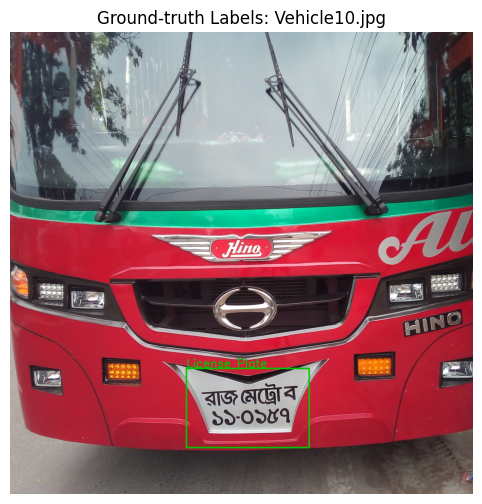

In [ ]:
from IPython.display import display, Markdown

idx = 1

example_img = sorted(glob.glob(f"{plate_dir}/train/images/*"))[idx]
example_label = label_path_for(example_img)

print("Image:", os.path.basename(example_img))
print("Label file:", os.path.basename(example_label))

with open(example_label) as f:
    raw_labels = f.read()

print("\nRaw YOLO label contents:")
print("-" * 60)
print(raw_labels)
print("-" * 60)


# 3. Display parsed labels as a table
label_df = read_yolo_labels(example_label, plate_names)

display(Markdown("### Parsed YOLO Labels"))
display(label_df)


# 4. Visualize the same image with ground-truth bounding boxes
plt.figure(figsize=(6, 6))

plt.imshow(draw_yolo_labels(example_img, plate_names))
plt.title(f"Ground-truth Labels: {os.path.basename(example_img)}")
plt.axis("off")

plt.show()

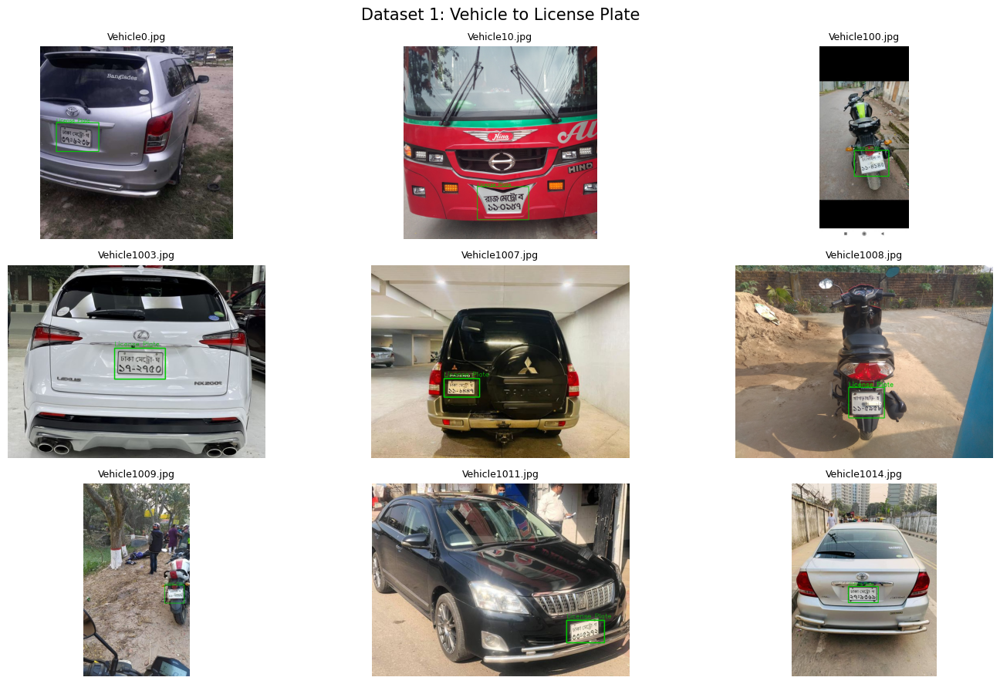

In [ ]:
# Visualize multiple examples from Dataset 1
images = sorted(glob.glob(f"{plate_dir}/train/images/*"))[:9]

cols = 3
rows = (len(images) + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(15, cols * rows))
axes = axes.flatten()

for ax, img_path in zip(axes, images):
    ax.imshow(draw_yolo_labels(img_path, plate_names))
    ax.set_title(os.path.basename(img_path), fontsize=9)
    ax.axis("off")

for ax in axes[len(images):]:
    ax.axis("off")

plt.suptitle("Dataset 1: Vehicle to License Plate", fontsize=15)
plt.tight_layout()
plt.show()

### 2.3 Train the plate detector

In [ ]:
# @title
%%html
<style>
.lp{font-family:system-ui,-apple-system,sans-serif;background:#ffffff;color:#1f2937;padding:20px 24px;border-radius:12px;border:1px solid #e5e7eb;max-width:960px;line-height:1.55;font-size:14px}
.lp h3{margin:16px 0 8px;color:#111827;font-size:16px}.lp h3:first-child{margin-top:0}
.lp .flow{display:flex;align-items:center;gap:8px;flex-wrap:wrap}
.lp .box{border-radius:10px;padding:10px 14px;text-align:center;flex:1;min-width:150px}
.lp .arrow{font-size:22px;color:#9ca3af}
.lp table{border-collapse:collapse;width:100%;font-size:13px}
.lp td,.lp th{border:1px solid #e5e7eb;padding:6px 8px;text-align:left}
.lp th{background:#f8fafc}
.lp code{background:#f3f4f6;padding:1px 5px;border-radius:4px;font-size:13px}
</style>
<div class="lp">
  <h3>Transfer learning: we don't start from zero</h3>
  <div class="flow">
    <div class="box" style="background:#f1f5f9;border:1px solid #cbd5e1"><b>yolo11s.pt</b><br><small>pretrained on COCO<br>80 classes, ~118k images<br>already knows edges, shapes, cars</small></div>
    <div class="arrow">➜</div>
    <div class="box" style="background:#fef3c7;border:1px solid #f59e0b"><b>Replace the head</b><br><small>80 classes → 1 class<br>(“Overriding nc=80 with nc=1”)</small></div>
    <div class="arrow">➜</div>
    <div class="box" style="background:#dcfce7;border:1px solid #22c55e"><b>Fine-tune</b><br><small>on 1,350 plate images<br>→ best.pt</small></div>
  </div>
  <h3>Training settings explained</h3>
  <table>
    <tr><th>Argument</th><th>Value</th><th>Meaning</th></tr>
    <tr><td><code>epochs</code></td><td>60</td><td>maximum passes over the training set</td></tr>
    <tr><td><code>imgsz</code></td><td>640</td><td>images are resized to 640×640. Vehicle photos need detail to spot a small plate.</td></tr>
    <tr><td><code>batch</code></td><td>16</td><td>images per gradient step (limited by GPU memory)</td></tr>
    <tr><td><code>patience</code></td><td>15</td><td><b>early stopping</b>: stop if val mAP hasn't improved for 15 epochs</td></tr>
    <tr><td><code>project / name</code></td><td>Drive / plate</td><td>where weights and plots are saved</td></tr>
  </table>
  <p>Watch the three losses (<code>box_loss</code>, <code>cls_loss</code>, <code>dfl_loss</code>) go <b>down</b> and <code>mAP50</code> go <b>up</b> in the log.</p>
</div>

Argument,Value,Meaning
epochs,60,maximum passes over the training set
imgsz,640,images are resized to 640×640. Vehicle photos need detail to spot a small plate.
batch,16,images per gradient step (limited by GPU memory)
patience,15,early stopping: stop if val mAP hasn't improved for 15 epochs
project / name,Drive / plate,where weights and plots are saved


In [ ]:
# Model 1: Vehicle -> License Plate (1 class)
from ultralytics import YOLO

plate_model = YOLO("yolo11s.pt")   # start from COCO-pretrained weights
plate_model.train(
    data=PLATE_YAML,
    epochs=60,
    imgsz=640,
    batch=16,
    patience=15,          # stop early if val mAP doesn't improve for 15 epochs
    project=RUNS_DIR,     # saved on Google Drive
    name="plate",
    exist_ok=True,
)

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/plate.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=plate, nbs=64, nms=None, opset=None, optimize=False, optimize

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x786ddb675160>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

### 2.4 Evaluate on the test set

In [ ]:
# Evaluate Model 1 on the TEST split (images never seen during training)
from ultralytics import YOLO
plate_model = YOLO(f"{RUNS_DIR}/plate/weights/best.pt")
m = plate_model.val(data=PLATE_YAML, split="test", project=RUNS_DIR, name="plate_test", exist_ok=True, verbose=False)
print(f"\nTEST  precision={m.box.mp:.3f}  recall={m.box.mr:.3f}  mAP50={m.box.map50:.3f}  mAP50-95={m.box.map:.3f}")

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.2±0.2 ms, read: 23.0±9.3 MB/s, size: 118.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/banglabengali-license-plate-with-number-detection/Vehicle_to_License_Plate/test/labels... 194 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 194/194 141.9it/s 1.4s
WARNING ⚠️ val: Cache directory /kaggle/input/banglabengali-license-plate-with-number-detection/Vehicle_to_License_Plate/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 2.4it/s 5.5s
                   all        194        200      0.972      0.975      0.983      0.605
Speed: 2.5ms preprocess

### 2.5 Inference

First on a single image, then ground truth vs prediction on several test images.


image 1/1 /kaggle/input/banglabengali-license-plate-with-number-detection/Vehicle_to_License_Plate/test/images/Vehicle1001.jpg: 480x640 1 License Plate, 17.3ms
Speed: 2.1ms preprocess, 17.3ms inference, 1.6ms postprocess per image at shape (1, 3, 480, 640)

1 detections:
  License Plate  conf=0.82  box=(144, 223, 233, 283)


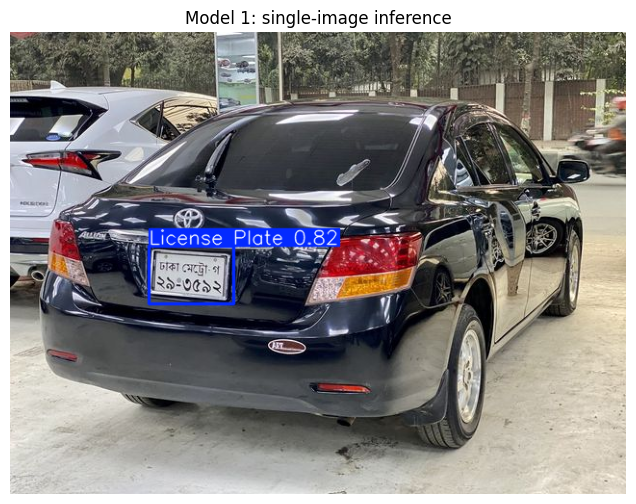

In [ ]:
# Inference on ONE image with Model 1 (vehicle -> plate)
plate_model = YOLO(f"{RUNS_DIR}/plate/weights/best.pt")
img_path = sorted(glob.glob(f"{plate_dir}/test/images/*"))[0]   # try any image path here

results = plate_model.predict(img_path, conf=0.4)   # returns a list: one Results object per image
r = results[0]

print(f"\n{len(r.boxes)} detections:")
for box in r.boxes:
    x1, y1, x2, y2 = box.xyxy[0].tolist()
    print(f"  {r.names[int(box.cls)]}  conf={float(box.conf):.2f}  box=({x1:.0f}, {y1:.0f}, {x2:.0f}, {y2:.0f})")

plt.figure(figsize=(8, 6))
plt.imshow(r.plot()[:, :, ::-1])   # r.plot() draws boxes, returns BGR
plt.axis("off"); plt.title("Model 1: single-image inference"); plt.show()

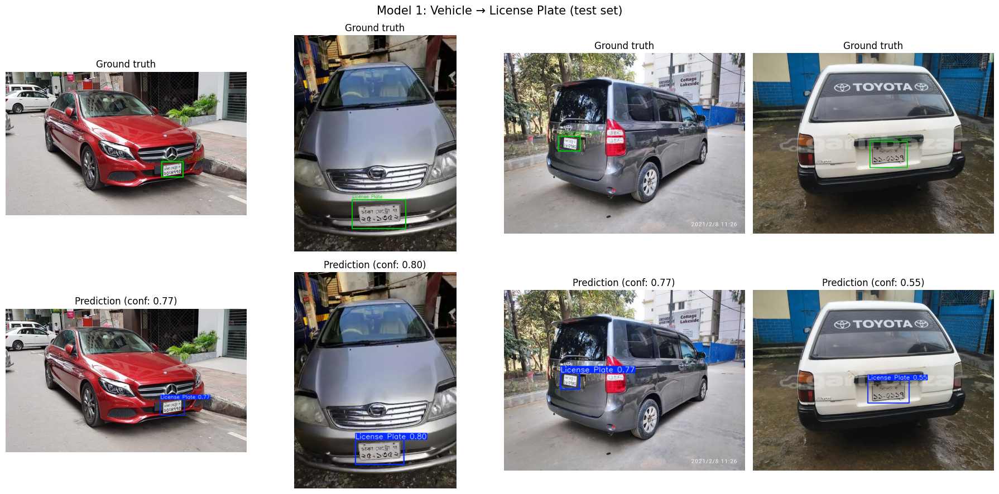

In [ ]:
# Visualize Model 1: ground truth (top) vs prediction (bottom) on test images
import random
plate_test_imgs = sorted(glob.glob(f"{plate_dir}/test/images/*"))
samples = random.Random(1).sample(plate_test_imgs, 4)

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for col, im in enumerate(samples):
    axes[0, col].imshow(draw_yolo_labels(im, plate_names))
    axes[0, col].set_title("Ground truth"); axes[0, col].axis("off")

    r = plate_model(im, conf=0.4, verbose=False)[0]
    axes[1, col].imshow(r.plot()[:, :, ::-1])   # r.plot() returns BGR
    confs = ", ".join(f"{c:.2f}" for c in r.boxes.conf.tolist()) or "nothing found"
    axes[1, col].set_title(f"Prediction (conf: {confs})"); axes[1, col].axis("off")
plt.suptitle("Model 1: Vehicle → License Plate (test set)", fontsize=15)
plt.tight_layout(); plt.show()

# 3. License Plate → Text Recognition

The second model looks at a **cropped plate** and detects every character or word on it: digits, Bangla letters, district names, and "Metro". This is still object detection, just with **102 classes**.

### 3.1 Check out the dataset config

In [ ]:
text_dir = os.path.join(DATASET_PATH, "License_Plate_to_Text")
yaml_path = os.path.join(text_dir, "data.yaml")

with open(yaml_path, "r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

print(yaml.safe_dump(data_config, sort_keys=False, allow_unicode=True))

train: ../train/images
val: ../val/images
test: ../test/images
nc: 102
names:
- '0'
- '1'
- '2'
- '3'
- '4'
- '5'
- '6'
- '7'
- '8'
- '9'
- Metro
- O
- Bh
- Ch
- Chh
- Do
- D
- E
- G
- Gh
- H
- J
- Jh
- K
- Kh
- L
- M
- N
- P
- S
- Sh
- T
- Thh
- Th
- U
- Bagerhat
- Bogura
- Bandarban
- Borguna
- Barishal
- Bhola
- Brahmanbaria
- Chandpur
- Chapainawabganj
- Chatt
- Chattogram
- Chuadanga
- Cox's Bazar
- Cumilla
- Dhaka
- Dinajpur
- Faridpur
- Feni
- Gaibandha
- Gazipur
- Gopalganj
- Habiganj
- Jamalpur
- Jashore
- Jhalokati
- Jhenaidah
- Joypurhat
- Khagrachari
- Khulna
- Kishoreganj
- Kurigram
- Kushtia
- Lakshmipur
- Lalmonirhat
- Madaripur
- Magura
- Manikganj
- Meherpur
- Moulvibazar
- Mymensingh
- Naogaon
- Narail
- Narayanganj
- Narsingdi
- Natore
- Netrokona
- Nilphamari
- Noakhali
- Pabna
- Panchagarh
- Patuakhali
- Pirojpur
- Raj
- Rajbari
- Rajshahi
- Rangamati
- Rangpur
- Satkhira
- Shariatpur
- Sherpur
- Sirajganj
- Sunamganj
- Sylhet
- Tangail
- Thakurgaon
- Dh
- B



### 3.2 Example images with labels

Image: 1.jpeg
Label file: 1.txt

Raw YOLO label contents:
------------------------------------------------------------
74 0.396552 0.382911 0.525862 0.272152
20 0.745690 0.287975 0.094828 0.170886
1 0.213362 0.816456 0.116379 0.240506
5 0.325431 0.794304 0.099138 0.259494
2 0.508621 0.724684 0.103448 0.259494
6 0.609914 0.683544 0.099138 0.177215
6 0.713362 0.674051 0.090517 0.208861
4 0.823276 0.617089 0.103448 0.183544

------------------------------------------------------------


### Parsed YOLO Labels

,class,x_center,y_center,width,height,class_name
0,74,0.396552,0.382911,0.525862,0.272152,Mymensingh
1,20,0.745690,0.287975,0.094828,0.170886,H
2,1,0.213362,0.816456,0.116379,0.240506,1
3,5,0.325431,0.794304,0.099138,0.259494,5
4,2,0.508621,0.724684,0.103448,0.259494,2
5,6,0.609914,0.683544,0.099138,0.177215,6
6,6,0.713362,0.674051,0.090517,0.208861,6
7,4,0.823276,0.617089,0.103448,0.183544,4


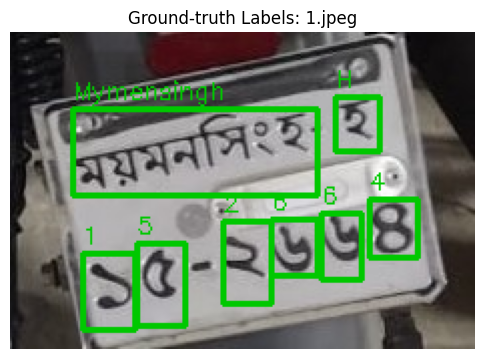

In [ ]:
idx = 1
example_img = sorted(glob.glob(f"{text_dir}/train/images/*"))[idx]
example_label = label_path_for(example_img)

print("Image:", os.path.basename(example_img))
print("Label file:", os.path.basename(example_label))

with open(example_label) as f:
    raw_labels = f.read()

print("\nRaw YOLO label contents:")
print("-" * 60)
print(raw_labels)
print("-" * 60)


# 3. Display parsed labels as a table
label_df = read_yolo_labels(example_label, text_names)

display(Markdown("### Parsed YOLO Labels"))
display(label_df)


# 4. Visualize the same image with ground-truth bounding boxes
plt.figure(figsize=(6, 6))

plt.imshow(draw_yolo_labels(example_img, text_names))
plt.title(f"Ground-truth Labels: {os.path.basename(example_img)}")
plt.axis("off")

plt.show()

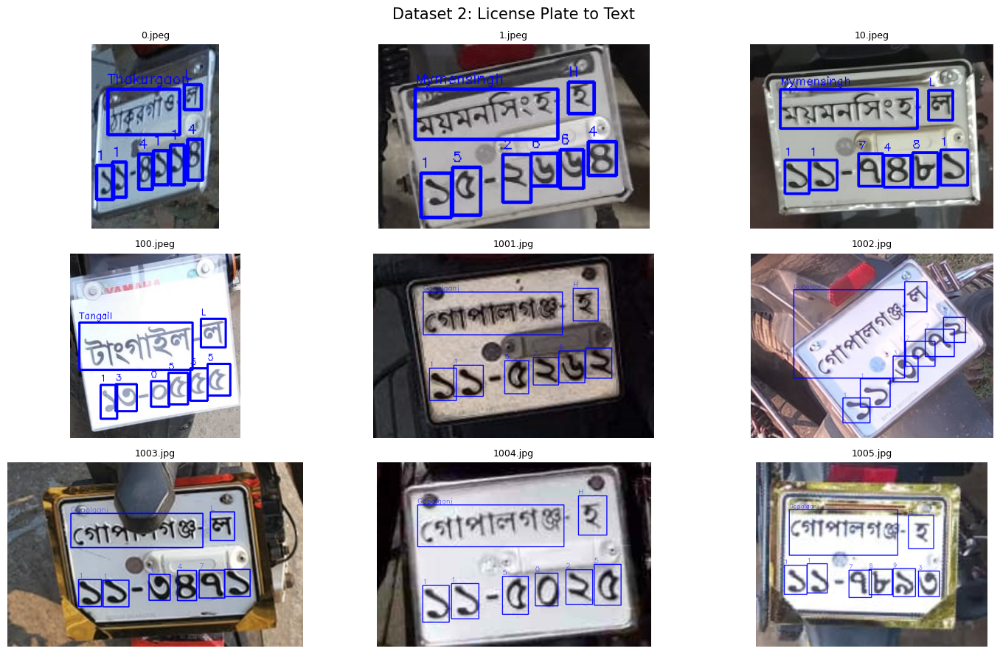

In [ ]:
# Visualize multiple examples from Dataset 2
images = sorted(glob.glob(f"{text_dir}/train/images/*"))[:9]

cols = 3
rows = (len(images) + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(15, cols * rows))
axes = axes.flatten()

for ax, img_path in zip(axes, images):
    ax.imshow(draw_yolo_labels(img_path, text_names, color=(255, 0, 0)))
    ax.set_title(os.path.basename(img_path), fontsize=9)
    ax.axis("off")

for ax in axes[len(images):]:
    ax.axis("off")

plt.suptitle("Dataset 2: License Plate to Text", fontsize=15)
plt.tight_layout()
plt.show()

### 3.3 Train the text detector

In [ ]:
# @title
%%html
<style>
.lp{font-family:system-ui,-apple-system,sans-serif;background:#ffffff;color:#1f2937;padding:20px 24px;border-radius:12px;border:1px solid #e5e7eb;max-width:960px;line-height:1.55;font-size:14px}
.lp h3{margin:16px 0 8px;color:#111827;font-size:16px}.lp h3:first-child{margin-top:0}
.lp .grid{display:grid;grid-template-columns:1fr 1fr;gap:20px;align-items:start}
@media (max-width:700px){.lp .grid{grid-template-columns:1fr}}
.lp .chips span{display:inline-block;border-radius:6px;padding:2px 8px;margin:2px;font-size:13px}
.lp .d{background:#dbeafe}.lp .l{background:#fde68a}.lp .w{background:#e9d5ff}.lp .m{background:#bbf7d0}
.lp code{background:#f3f4f6;padding:1px 5px;border-radius:4px;font-size:13px}
.lp .warn{background:#fff7ed;border-left:4px solid #f97316;padding:8px 12px;margin-top:12px}
</style>
<div class="lp">
  <div class="grid">
    <div>
      <h3>A Bangladeshi plate has two lines</h3>
      <svg viewBox="0 0 340 150" style="width:100%;max-width:360px">
        <rect x="5" y="5" width="330" height="140" rx="10" fill="#ffffff" stroke="#111827" stroke-width="3"/>
        <rect x="30" y="20" width="80" height="45" fill="none" stroke="#7c3aed" stroke-width="2"/>
        <rect x="120" y="20" width="95" height="45" fill="none" stroke="#16a34a" stroke-width="2"/>
        <rect x="225" y="20" width="40" height="45" fill="none" stroke="#d97706" stroke-width="2"/>
        <text x="40" y="52" font-size="24">ঢাকা</text><text x="125" y="52" font-size="24">মেট্রো</text><text x="234" y="52" font-size="24">গ</text>
        <g stroke="#2563eb" stroke-width="2" fill="none">
          <rect x="40" y="80" width="34" height="50"/><rect x="78" y="80" width="34" height="50"/>
          <rect x="140" y="80" width="34" height="50"/><rect x="178" y="80" width="34" height="50"/><rect x="216" y="80" width="34" height="50"/><rect x="254" y="80" width="34" height="50"/>
        </g>
        <text x="46" y="118" font-size="30">১</text><text x="84" y="118" font-size="30">১</text><text x="118" y="118" font-size="30">-</text>
        <text x="146" y="118" font-size="30">২</text><text x="184" y="118" font-size="30">৩</text><text x="222" y="118" font-size="30">৪</text><text x="260" y="118" font-size="30">৫</text>
      </svg>
      <p>Each colored rectangle is <b>one detection</b>. The model only outputs boxes and classes, not text. Turning them into a string is the pipeline's job (Section 4).</p>
    </div>
    <div>
      <h3>The 102 classes</h3>
      <div class="chips">
        <span class="d">0 – 9 digits</span><span class="d">ids 0–9</span><br>
        <span class="m">Metro</span><span class="m">id 10</span><br>
        <span class="l">অ ভ চ ছ ড দ এ গ ঘ হ জ ঝ ক খ ল ম ন প স শ ট ঠ থ উ ঢ ব</span><span class="l">letters</span><br>
        <span class="w">Dhaka, Chattogram, Sylhet, Khulna, … 64 districts</span><span class="w">words</span>
      </div>
      <p>Whole district names are single classes, so the model detects <b>"Dhaka"</b> as one box instead of reading 4 letters.</p>
      <h3>Settings that differ from Model 1</h3>
      <ul style="padding-left:20px;margin:0">
        <li><code>imgsz=480</code>: plate crops are small (~557×370), so 640 would waste compute.</li>
        <li><code>batch=32</code>: smaller images let more fit on the GPU.</li>
        <li><code>epochs=100, patience=20</code>: more classes take longer to learn.</li>
      </ul>
    </div>
  </div>
  <div class="warn">⚠️ <b>Augmentation must make sense for the data.</b> By default YOLO randomly mirrors images left↔right (<code>fliplr=0.5</code>). That's fine for cars, but a mirrored "৩" is not a "৩", and it would teach the model nonsense. So we set <code>fliplr=0.0</code>.</div>
</div>

In [ ]:
# Model 2: License Plate -> Characters/words (102 classes)
text_model = YOLO("yolo11s.pt")
text_model.train(
    data=TEXT_YAML,
    epochs=100,
    imgsz=480,            # plate crops are ~557x370
    batch=32,
    patience=20,
    fliplr=0.0,           # no horizontal flip: mirrored characters are not valid characters
    project=RUNS_DIR,
    name="text",
    exist_ok=True,
)

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/text.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=480, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=text, nbs=64, nms=None, opset=None, optimize=False, optimizer

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,  53,  54,  55,  56,  57,  58,  59,  60,  61,
        62,  63,  64,  65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x786db7fe1a20>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.0

### 3.4 Evaluate on the test set

In [ ]:
# Evaluate Model 2 on the TEST split
text_model = YOLO(f"{RUNS_DIR}/text/weights/best.pt")
m = text_model.val(data=TEXT_YAML, split="test", project=RUNS_DIR, name="text_test", exist_ok=True, verbose=False)
print(f"\nTEST  precision={m.box.mp:.3f}  recall={m.box.mr:.3f}  mAP50={m.box.map50:.3f}  mAP50-95={m.box.map:.3f}")

# Which classes are hardest? (per-class AP50-95, only classes present in the test set)
per_class = sorted(zip(m.box.ap_class_index, m.box.maps[m.box.ap_class_index]), key=lambda t: t[1])
print("\n5 hardest classes:", ", ".join(f"{text_model.names[int(c)]}={ap:.2f}" for c, ap in per_class[:5]))
print("5 easiest classes:", ", ".join(f"{text_model.names[int(c)]}={ap:.2f}" for c, ap in per_class[-5:]))

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,452,274 parameters, 0 gradients, 21.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.4 ms, read: 10.9±5.0 MB/s, size: 64.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/banglabengali-license-plate-with-number-detection/License_Plate_to_Text/test/labels... 267 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 267/267 140.4it/s 1.9s
WARNING ⚠️ val: Cache directory /kaggle/input/banglabengali-license-plate-with-number-detection/License_Plate_to_Text/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 4.6it/s 3.7s
                   all        267       2199      0.933      0.934      0.983        0.7
Speed: 0.8ms preprocess, 6.1ms

### 3.5 Inference

First on a single image, then ground truth vs prediction on several test plates.


image 1/1 /kaggle/input/banglabengali-license-plate-with-number-detection/License_Plate_to_Text/test/images/101.jpeg: 416x480 1 0, 1 1, 1 2, 1 3, 1 5, 1 7, 1 H, 1 Tangail, 17.0ms
Speed: 1.1ms preprocess, 17.0ms inference, 1.4ms postprocess per image at shape (1, 3, 416, 480)

8 detections:
  7            conf=0.87  box=(98, 88, 119, 116)
  0            conf=0.86  box=(118, 87, 138, 114)
  5            conf=0.86  box=(138, 87, 157, 112)
  3            conf=0.83  box=(45, 92, 66, 118)
  2            conf=0.83  box=(79, 90, 98, 116)
  1            conf=0.82  box=(25, 93, 45, 120)
  H            conf=0.72  box=(122, 37, 143, 64)
  Tangail      conf=0.70  box=(23, 36, 115, 72)


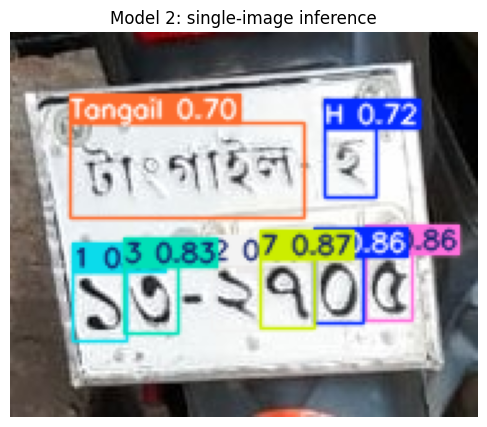

In [ ]:
# Inference on ONE image with Model 2 (plate -> characters)
text_model = YOLO(f"{RUNS_DIR}/text/weights/best.pt")
img_path = sorted(glob.glob(f"{text_dir}/test/images/*"))[0]   # try any plate image path here

results = text_model.predict(img_path, conf=0.3)   # returns a list: one Results object per image
r = results[0]

print(f"\n{len(r.boxes)} detections:")
for box in r.boxes:
    x1, y1, x2, y2 = box.xyxy[0].tolist()
    print(f"  {r.names[int(box.cls)]:<12} conf={float(box.conf):.2f}  box=({x1:.0f}, {y1:.0f}, {x2:.0f}, {y2:.0f})")

plt.figure(figsize=(8, 5))
plt.imshow(r.plot(line_width=1, font_size=10)[:, :, ::-1])   # r.plot() draws boxes, returns BGR
plt.axis("off"); plt.title("Model 2: single-image inference"); plt.show()

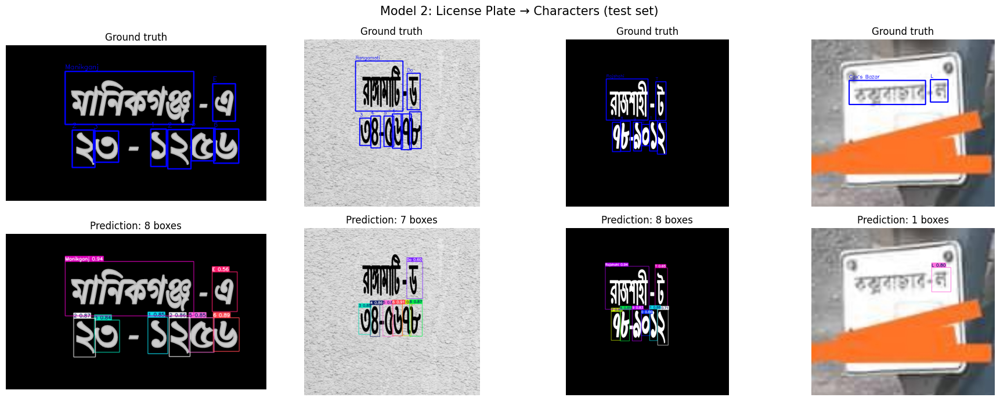

In [ ]:
# Visualize Model 2: ground truth (top) vs prediction (bottom) on test plate images
text_test_imgs = sorted(glob.glob(f"{text_dir}/test/images/*"))
samples = random.Random(2).sample(text_test_imgs, 4)

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for col, im in enumerate(samples):
    axes[0, col].imshow(draw_yolo_labels(im, text_names, (255, 0, 0)))
    axes[0, col].set_title("Ground truth"); axes[0, col].axis("off")

    r = text_model(im, conf=0.3, verbose=False)[0]
    axes[1, col].imshow(r.plot(line_width=1, font_size=10)[:, :, ::-1])
    axes[1, col].set_title(f"Prediction: {len(r.boxes)} boxes"); axes[1, col].axis("off")
plt.suptitle("Model 2: License Plate → Characters (test set)", fontsize=15)
plt.tight_layout(); plt.show()

# 4. End-to-End Pipeline: Image → Plate Text

Now we chain the two models. The diagram shows the 5 steps. The code below implements them in `read_plates()`. After that we run it on a **real test image** and display every intermediate stage.

In [ ]:
# @title
%%html
<style>
.lp{font-family:system-ui,-apple-system,sans-serif;background:#ffffff;color:#1f2937;padding:20px 24px;border-radius:12px;border:1px solid #e5e7eb;max-width:960px;line-height:1.5;font-size:14px}
.lp h3{margin:0 0 12px;color:#111827}
.lp .steps{display:grid;grid-template-columns:repeat(5,1fr);gap:10px}
@media (max-width:800px){.lp .steps{grid-template-columns:1fr}}
.lp .s{border-radius:10px;padding:10px;border:1px solid #e5e7eb;background:#f8fafc;position:relative}
.lp .s .n{display:inline-block;background:#111827;color:#fff;border-radius:50%;width:22px;height:22px;text-align:center;line-height:22px;font-size:12px;margin-right:4px}
.lp .s b{font-size:14px}
.lp .s p{margin:6px 0 0;font-size:12.5px;color:#374151}
.lp .tag{display:inline-block;font-size:11px;border-radius:4px;padding:1px 6px;margin-top:6px}
.lp .yolo{background:#fef3c7;border:1px solid #f59e0b}.lp .py{background:#ecfeff;border:1px solid #67e8f9}
.lp code{background:#e5e7eb;padding:0 4px;border-radius:3px;font-size:12px}
.lp svg{width:100%;margin-top:6px}
</style>
<div class="lp">
  <h3>Inside <code>read_plates(image)</code></h3>
  <div class="steps">
    <div class="s"><span class="n">1</span><b>Detect plate</b>
      <svg viewBox="0 0 120 70"><rect x="2" y="2" width="116" height="66" rx="4" fill="#e2e8f0"/><path d="M15,50 L30,30 L90,30 L105,50 Z" fill="#94a3b8"/><rect x="45" y="44" width="30" height="12" fill="#fff" stroke="#f59e0b" stroke-width="2.5"/></svg>
      <p><code>plate_model(img)</code> returns plate boxes and confidences.</p><span class="tag yolo">Model 1</span></div>
    <div class="s"><span class="n">2</span><b>Crop + pad</b>
      <svg viewBox="0 0 120 70"><rect x="20" y="15" width="80" height="40" fill="#fff" stroke="#111827" stroke-width="2"/><rect x="14" y="11" width="92" height="48" fill="none" stroke="#9ca3af" stroke-dasharray="4 3"/></svg>
      <p>Cut the plate out with <b>5% extra margin</b> so edge characters aren't clipped.</p><span class="tag py">Python</span></div>
    <div class="s"><span class="n">3</span><b>Detect characters</b>
      <svg viewBox="0 0 120 70"><rect x="10" y="5" width="100" height="60" fill="#fff" stroke="#111827" stroke-width="2"/><g fill="none" stroke-width="1.5"><rect x="18" y="12" width="28" height="16" stroke="#7c3aed"/><rect x="50" y="12" width="32" height="16" stroke="#16a34a"/><rect x="86" y="12" width="14" height="16" stroke="#d97706"/></g><g fill="none" stroke="#2563eb" stroke-width="1.5"><rect x="18" y="36" width="11" height="22"/><rect x="31" y="36" width="11" height="22"/><rect x="50" y="36" width="11" height="22"/><rect x="63" y="36" width="11" height="22"/><rect x="76" y="36" width="11" height="22"/><rect x="89" y="36" width="11" height="22"/></g></svg>
      <p><code>text_model(crop)</code> returns ~9 boxes in <b>random order</b>.</p><span class="tag yolo">Model 2</span></div>
    <div class="s"><span class="n">4</span><b>Group into lines</b>
      <svg viewBox="0 0 120 70"><rect x="4" y="8" width="112" height="22" rx="4" fill="rgba(124,58,237,.12)" stroke="#7c3aed" stroke-dasharray="3 2"/><rect x="4" y="36" width="112" height="26" rx="4" fill="rgba(37,99,235,.12)" stroke="#2563eb" stroke-dasharray="3 2"/><text x="8" y="23" font-size="9">line 1</text><text x="8" y="53" font-size="9">line 2</text><path d="M108,12 v46" stroke="#111827" marker-end="url(#a)"/><defs><marker id="a" markerWidth="6" markerHeight="6" refX="3" refY="3" orient="auto"><path d="M0,0 L6,3 L0,6 Z"/></marker></defs></svg>
      <p>Sort by vertical center. A <b>jump larger than half a box height</b> starts a new line.</p><span class="tag py">Python</span></div>
    <div class="s"><span class="n">5</span><b>Read left→right</b>
      <div style="margin-top:8px;background:#dcfce7;border:1px solid #22c55e;border-radius:6px;padding:8px;text-align:center;font-size:15px">ঢাকা মেট্রো গ<br>১১-২৩৪৫</div>
      <p>Sort each line by x. Digits are joined (<code>112345</code>), then formatted <code>NN-NNNN</code>.</p><span class="tag py">Python</span></div>
  </div>
</div>

### 4.1 The `read_plates()` function

In [ ]:
import numpy as np, cv2
from ultralytics import YOLO

plate_model = YOLO(f"{RUNS_DIR}/plate/weights/best.pt")
text_model = YOLO(f"{RUNS_DIR}/text/weights/best.pt")

EN_NAMES = text_model.names
BN_NAMES = yaml.safe_load(open(os.path.join(path, "License_Plate_to_Text/data-bn.yaml")))["names"]
BN_NAMES[0] = "০"         # source file has a Latin "0"
BN_NAMES[38] = "বরগুনা"   # source file repeats বাগেরহাট here; English list says Borguna

def _rows(boxes):
    """Group char boxes [(x1,y1,x2,y2,cls)] into text lines, top-to-bottom, left-to-right."""
    if not boxes:
        return []
    boxes = sorted(boxes, key=lambda b: (b[1] + b[3]) / 2)
    med_h = np.median([b[3] - b[1] for b in boxes])
    rows, cur = [], [boxes[0]]
    for b in boxes[1:]:
        cy = (b[1] + b[3]) / 2
        cur_cy = np.mean([(c[1] + c[3]) / 2 for c in cur])
        if cy - cur_cy > 0.5 * med_h:
            rows.append(cur); cur = [b]
        else:
            cur.append(b)
    rows.append(cur)
    return [sorted(r, key=lambda b: b[0]) for r in rows]

def _join(row, names):
    """Digits (classes 0-9) are concatenated; words are space-separated. 6-digit runs become NN-NNNN."""
    tokens = []
    for _, _, _, _, c in row:
        if c <= 9 and tokens and tokens[-1][1]:
            tokens[-1][0] += names[c]
        else:
            tokens.append([names[c], c <= 9])
    return " ".join(t[:2] + "-" + t[2:] if is_num and len(t) == 6 else t for t, is_num in tokens)

def read_plates(image, plate_conf=0.4, char_conf=0.3, pad=0.05):
    """image: path or BGR ndarray. Returns list of {box, conf, text_en, text_bn}, highest-confidence first."""
    img = cv2.imread(image) if isinstance(image, str) else image
    H, W = img.shape[:2]
    det = plate_model(img, conf=plate_conf, verbose=False)[0].boxes
    results = []
    for (x1, y1, x2, y2), conf in zip(det.xyxy.cpu().numpy(), det.conf.cpu().numpy()):
        px, py = (x2 - x1) * pad, (y2 - y1) * pad
        x1, y1 = int(max(0, x1 - px)), int(max(0, y1 - py))
        x2, y2 = int(min(W, x2 + px)), int(min(H, y2 + py))
        r = text_model(img[y1:y2, x1:x2], conf=char_conf, verbose=False)[0].boxes
        chars = [(*b, int(c)) for b, c in zip(r.xyxy.cpu().numpy(), r.cls.cpu().numpy())]
        rows = _rows(chars)
        results.append({
            "box": (x1, y1, x2, y2), "conf": float(conf),
            "text_en": " / ".join(_join(row, EN_NAMES) for row in rows),
            "text_bn": " / ".join(_join(row, BN_NAMES) for row in rows),
        })
    return sorted(results, key=lambda d: -d["conf"])

### 4.2 Run on test images

In [ ]:
# Demo on held-out test images
import random
test_imgs = sorted(glob.glob(os.path.join(path, "Vehicle_to_License_Plate/test/images/*")))
for im in random.Random(0).sample(test_imgs, 8):
    print(os.path.basename(im), "->", [(p["text_en"], p["text_bn"], round(p["conf"], 2)) for p in read_plates(im)])

Vehicle1854.jpeg -> [('Dhaka Metro / 1383 Ch / 91', 'ঢাকা মেট্রো / ১৩৮৩ চ / ৯১', 0.78)]
Vehicle1896.jpeg -> [('Dhaka Metro G / 26-8490', 'ঢাকা মেট্রো গ / ২৬-৮৪৯০', 0.79)]
Vehicle1122.jpg -> [('Dhaka Metro G / 25-6198', 'ঢাকা মেট্রো গ / ২৫-৬১৯৮', 0.78)]
Vehicle1561.jpg -> [('Dhaka Metro G / 25-2032', 'ঢাকা মেট্রো গ / ২৫-২০৩২', 0.79)]
Vehicle396.jpg -> [('L / Khagrachari H / 11-5309', 'ল / খাগড়াছড়ি হ / ১১-৫৩০৯', 0.78)]
Vehicle337.jpg -> [('Dhaka Metro Bh / 14-0082', 'ঢাকা মেট্রো ভ / ১৪-০০৮২', 0.72)]
Vehicle1886.jpeg -> [('Metro H / Dhaka / 5879 / 22', 'মেট্রো হ / ঢাকা / ৫৮৭৯ / ২২', 0.79)]
Vehicle1655.jpg -> [('Chattogram Th / 14-1969', 'চট্টগ্রাম থ / ১৪-১৯৬৯', 0.78)]


### 4.3 Step-by-step visualization with real images


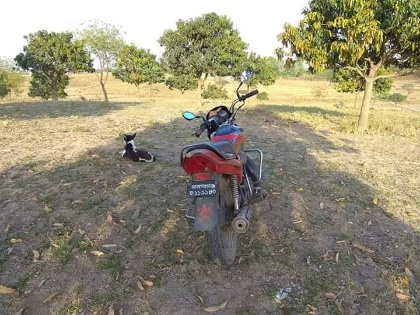
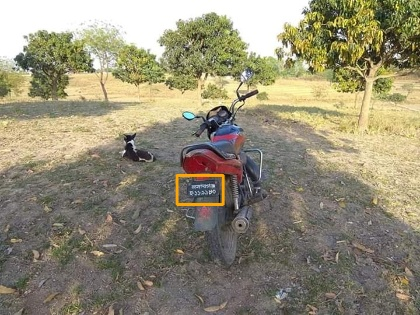
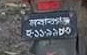
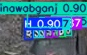
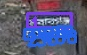


...


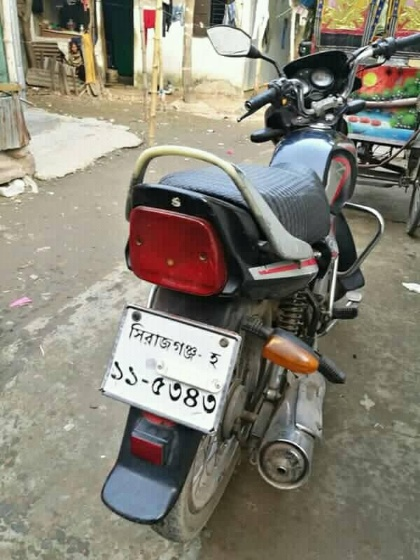
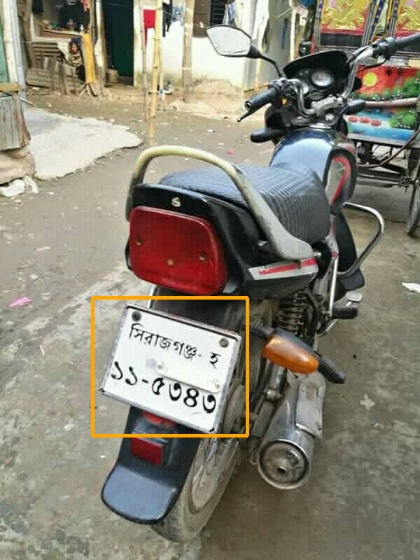
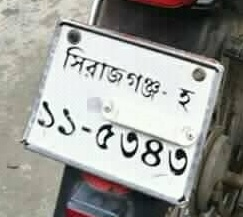
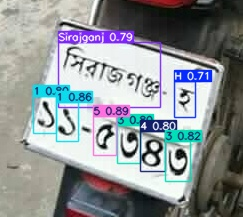
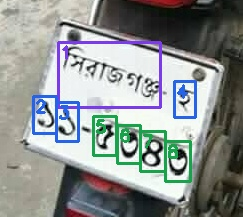

In [ ]:
# @title
# Pipeline diagram with REAL images: run each step on a test image and show what it produces
import base64
from IPython.display import HTML, display

def to_b64(img_bgr, max_w=420):
    h, w = img_bgr.shape[:2]
    if w > max_w:
        img_bgr = cv2.resize(img_bgr, (max_w, int(h * max_w / w)))
    return base64.b64encode(cv2.imencode(".jpg", img_bgr)[1]).decode()

def pipeline_diagram(img_path, pad=0.05):
    img = cv2.imread(img_path)
    H, W = img.shape[:2]

    # Step 1: detect plate
    det = plate_model(img, conf=0.4, verbose=False)[0]
    if len(det.boxes) == 0:
        return None
    best = det.boxes.conf.argmax()
    x1, y1, x2, y2 = det.boxes.xyxy[best].tolist()
    step1 = img.copy()
    cv2.rectangle(step1, (int(x1), int(y1)), (int(x2), int(y2)), (0, 165, 255), max(3, W // 150))

    # Step 2: crop with padding
    px, py = (x2 - x1) * pad, (y2 - y1) * pad
    x1, y1, x2, y2 = int(max(0, x1 - px)), int(max(0, y1 - py)), int(min(W, x2 + px)), int(min(H, y2 + py))
    crop = img[y1:y2, x1:x2]

    # Step 3: detect characters
    r = text_model(crop, conf=0.3, verbose=False)[0]
    step3 = r.plot(line_width=1, font_size=9)

    # Step 4: group into lines and number them in reading order
    chars = [(*b, int(c)) for b, c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy())]
    rows = _rows(chars)
    step4 = crop.copy()
    colors = [(237, 58, 124), (235, 99, 37), (74, 163, 22)]
    k = 0
    for i, row in enumerate(rows):
        for (a, b, c, d, _) in row:
            k += 1
            cv2.rectangle(step4, (int(a), int(b)), (int(c), int(d)), colors[i % 3], 2)
            cv2.putText(step4, str(k), (int(a) + 2, int(b) + 16), cv2.FONT_HERSHEY_SIMPLEX, 0.55, colors[i % 3], 2)

    # Step 5: text
    text_en = " / ".join(_join(row, EN_NAMES) for row in rows)
    text_bn = "<br>".join(_join(row, BN_NAMES) for row in rows)

    stages = [
        ("Input image", to_b64(img), "the original vehicle photo"),
        ("① Model 1: plate detected", to_b64(step1), f"confidence {det.boxes.conf[best]:.2f}"),
        ("② Crop + 5% padding", to_b64(crop, 300), f"{crop.shape[1]}×{crop.shape[0]} px"),
        ("③ Model 2: characters", to_b64(step3, 300), f"{len(chars)} boxes, unordered"),
        ("④ Grouped into lines", to_b64(step4, 300), f"{len(rows)} line(s), numbers = reading order"),
    ]
    cards = "".join(
        f'<div class="st"><div class="t">{t}</div><img src="data:image/jpeg;base64,{b}"><div class="c">{c}</div></div><div class="ar">➜</div>'
        for t, b, c in stages)
    html = f"""
      <style>
      .pd{{font-family:system-ui,sans-serif;background:#fff;color:#1f2937;padding:16px;border-radius:12px;border:1px solid #e5e7eb}}
      .pd .row{{display:flex;align-items:center;gap:8px;flex-wrap:wrap}}
      .pd .st{{flex:1;min-width:170px;max-width:260px;background:#f8fafc;border:1px solid #e5e7eb;border-radius:10px;padding:8px;text-align:center}}
      .pd .st img{{width:100%;border-radius:6px}}
      .pd .t{{font-weight:700;font-size:13px;margin-bottom:6px}} .pd .c{{font-size:12px;color:#6b7280;margin-top:4px}}
      .pd .ar{{font-size:22px;color:#9ca3af}}
      .pd .out{{flex:1;min-width:170px;background:#dcfce7;border:2px solid #22c55e;border-radius:10px;padding:12px;text-align:center}}
      .pd .bn{{font-size:24px;font-weight:700;line-height:1.4}} .pd .en{{font-size:13px;color:#166534;margin-top:6px}}
      </style>
      <div class="pd"><div class="row">{cards}
        <div class="out"><div class="t">⑤ Final text</div><div class="bn">{text_bn}</div><div class="en">{text_en}</div></div>
      </div></div>"""


    return html

for im in random.Random(3).sample(sorted(glob.glob(f"{plate_dir}/test/images/*")), 3):
    h = pipeline_diagram(im)
    if h:
        display(HTML(h))

### 4.4 Results grid

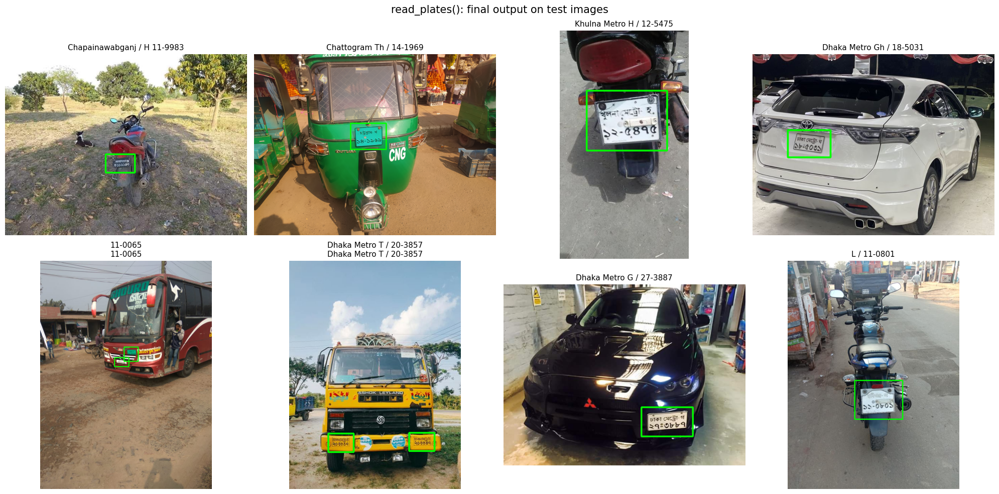

In [ ]:
# Visualize the full pipeline on a grid of test images
samples = random.Random(4).sample(sorted(glob.glob(f"{plate_dir}/test/images/*")), 8)
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, im in zip(axes.flat, samples):
    img = cv2.imread(im)
    plates = read_plates(img)
    for p in plates:
        x1, y1, x2, y2 = p["box"]
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), max(3, img.shape[1] // 200))
    ax.imshow(img[:, :, ::-1]); ax.axis("off")
    ax.set_title("\n".join(p["text_en"] for p in plates) or "no plate found", fontsize=11)
plt.suptitle("read_plates(): final output on test images", fontsize=15)
plt.tight_layout(); plt.show()

# 5. Improving Object Detection Accuracy

In [ ]:
# @title

%%html
<div style="font-family:Arial,sans-serif; line-height:1.65; color:#263238; max-width:1000px; margin:auto;">

  <div style="background:#172554; color:white; padding:24px; border-radius:12px; margin-bottom:22px;">
    <div style="font-size:13px; opacity:.8; letter-spacing:1px;">OBJECT DETECTION · MODEL OPTIMIZATION</div>
    <h2 style="margin:8px 0; color:white;">Improving Object Detection Accuracy</h2>
    <p style="margin:0; color:#dbeafe;">
      Better detection does not always require a bigger model. Dataset quality,
      annotations, training configuration, and inference settings all matter.
    </p>
  </div>

  <div style="background:#eff6ff; border-left:4px solid #2563eb; padding:15px 18px; border-radius:6px; margin-bottom:24px;">
    <strong>Remember:</strong> Before changing the model, investigate where and why
    it is making incorrect predictions.
  </div>

  <h3>1. Improve Dataset Quality</h3>
  <p>
    The model learns from the examples we provide. If images or annotations are
    incorrect, the model can learn incorrect patterns.
  </p>

  <div style="display:grid; grid-template-columns:repeat(auto-fit,minmax(210px,1fr)); gap:12px; margin:16px 0;">
    <div style="background:#f0fdf4; padding:15px; border-radius:9px;">
      <strong style="color:#166534;">Clean images</strong>
      <ul style="margin-bottom:0; padding-left:20px;">
        <li>Remove corrupted images.</li>
        <li>Remove unnecessary duplicates.</li>
        <li>Check image-label matching.</li>
      </ul>
    </div>
    <div style="background:#eff6ff; padding:15px; border-radius:9px;">
      <strong style="color:#1d4ed8;">Correct annotations</strong>
      <ul style="margin-bottom:0; padding-left:20px;">
        <li>Fix incorrect class IDs.</li>
        <li>Use tight bounding boxes.</li>
        <li>Ensure objects are not missed.</li>
      </ul>
    </div>
    <div style="background:#f5f3ff; padding:15px; border-radius:9px;">
      <strong style="color:#6d28d9;">Increase diversity</strong>
      <ul style="margin-bottom:0; padding-left:20px;">
        <li>Different backgrounds.</li>
        <li>Different lighting conditions.</li>
        <li>Different angles and object sizes.</li>
      </ul>
    </div>
  </div>

  <p style="background:#fff7ed; padding:12px 15px; border-radius:7px; color:#9a3412;">
    <strong>Important:</strong> Poor annotations teach the model incorrect information.
    More training cannot reliably compensate for bad labels.
  </p>

  <hr style="border:0; border-top:1px solid #e5e7eb; margin:26px 0;">

  <h3>2. Handle Class Imbalance</h3>
  <p>
    Class imbalance occurs when some classes have significantly more training
    examples than others. The model may struggle to learn classes with very few
    examples.
  </p>

  <table style="width:100%; border-collapse:collapse; margin:15px 0;">
    <thead>
      <tr style="background:#f1f5f9;">
        <th style="padding:11px; text-align:left;">Class</th>
        <th style="padding:11px; text-align:right;">Number of Images</th>
      </tr>
    </thead>
    <tbody>
      <tr><td style="padding:10px; border-bottom:1px solid #e5e7eb;">Person</td><td style="padding:10px; text-align:right; border-bottom:1px solid #e5e7eb;">10,000</td></tr>
      <tr><td style="padding:10px; border-bottom:1px solid #e5e7eb;">Helmet</td><td style="padding:10px; text-align:right; border-bottom:1px solid #e5e7eb;">8,000</td></tr>
      <tr style="background:#fff7ed;"><td style="padding:10px; border-bottom:1px solid #e5e7eb;"><strong>Safety Vest</strong></td><td style="padding:10px; text-align:right; border-bottom:1px solid #e5e7eb;"><strong>500</strong></td></tr>
    </tbody>
  </table>

  <p>The model sees far fewer safety vest examples than person examples.</p>

  <strong>Possible solutions:</strong>
  <ul>
    <li>Collect more images of underrepresented classes.</li>
    <li>Apply suitable augmentation to rare-class examples.</li>
    <li>Oversample images containing rare classes.</li>
    <li>Review precision, recall, and mAP for each class.</li>
  </ul>

  <p style="font-size:13px; color:#64748b;">
    Note: Image count is only an approximation. Also inspect the number of
    annotated object instances per class.
  </p>

  <hr style="border:0; border-top:1px solid #e5e7eb; margin:26px 0;">

  <h3>3. Use Data Augmentation</h3>
  <p>
    Data augmentation creates variations of training images. This helps the model
    generalize to images that look different from the original training examples.
  </p>

  <div style="display:grid; grid-template-columns:repeat(auto-fit,minmax(145px,1fr)); gap:10px; margin:15px 0;">
    <div style="background:#f8fafc; padding:13px; border-radius:8px;"><strong>Flip</strong><br><span style="font-size:13px; color:#64748b;">Mirror an image horizontally.</span></div>
    <div style="background:#f8fafc; padding:13px; border-radius:8px;"><strong>Scaling</strong><br><span style="font-size:13px; color:#64748b;">Make objects appear larger or smaller.</span></div>
    <div style="background:#f8fafc; padding:13px; border-radius:8px;"><strong>Translation</strong><br><span style="font-size:13px; color:#64748b;">Shift image content.</span></div>
    <div style="background:#f8fafc; padding:13px; border-radius:8px;"><strong>Rotation</strong><br><span style="font-size:13px; color:#64748b;">Rotate images by small angles.</span></div>
    <div style="background:#f8fafc; padding:13px; border-radius:8px;"><strong>Color changes</strong><br><span style="font-size:13px; color:#64748b;">Change brightness and color.</span></div>
    <div style="background:#f8fafc; padding:13px; border-radius:8px;"><strong>Mosaic / MixUp</strong><br><span style="font-size:13px; color:#64748b;">Combine multiple training examples.</span></div>
  </div>

  <strong>Example: Configure augmentation in Ultralytics</strong>
  <pre style="background:#0f172a; color:#e2e8f0; padding:17px; border-radius:9px; overflow-x:auto;"><code>model.train(
    data="dataset.yaml",
    epochs=100,
    imgsz=640,
    fliplr=0.5,
    degrees=10,
    scale=0.5,
    mosaic=1.0
)</code></pre>

  <p>
    These are example settings, not universal best values. For example,
    <code>fliplr=0.5</code> means horizontal flipping is applied with a
    probability of 50%.
  </p>

  <div style="background:#fff7ed; padding:13px 16px; border-radius:8px; color:#9a3412;">
    <strong>Use realistic augmentation:</strong> A vertical flip may be inappropriate
    for a normal CCTV object detection task. Augmentation should reflect the
    variations expected in the real environment.
  </div>

  <hr style="border:0; border-top:1px solid #e5e7eb; margin:26px 0;">

  <h3>4. Increase Image Resolution</h3>
  <p>
    Small objects contain fewer pixels. At low resolution, important details may
    disappear, making detection difficult.
  </p>

  <div style="background:#f8fafc; padding:16px; border-radius:9px; margin:15px 0;">
    <strong>Example: Train with a larger image size</strong>
    <pre style="background:#0f172a; color:#e2e8f0; padding:14px; border-radius:7px; overflow-x:auto;"><code>model.train(
    data="dataset.yaml",
    epochs=100,
    imgsz=960
)</code></pre>
  </div>

  <strong>Trade-offs:</strong>
  <ul>
    <li>Higher resolution consumes more GPU memory.</li>
    <li>Training and inference become slower.</li>
    <li>Accuracy does not necessarily improve.</li>
  </ul>

  <p>
    Try different image sizes and compare validation metrics, especially when
    detecting small objects such as license plates.
  </p>

  <hr style="border:0; border-top:1px solid #e5e7eb; margin:26px 0;">

  <h3>5. Choose the Right Model Size</h3>
  <p>
    Ultralytics provides model variants with different computational requirements
    and capacities.
  </p>

  <table style="width:100%; border-collapse:collapse; margin:15px 0;">
    <thead>
      <tr style="background:#f1f5f9;">
        <th style="padding:11px; text-align:left;">Variant</th>
        <th style="padding:11px; text-align:left;">Characteristics</th>
      </tr>
    </thead>
    <tbody>
      <tr><td style="padding:10px; border-bottom:1px solid #e5e7eb;"><strong>Nano (n)</strong></td><td style="padding:10px; border-bottom:1px solid #e5e7eb;">Very fast and lightweight.</td></tr>
      <tr><td style="padding:10px; border-bottom:1px solid #e5e7eb;"><strong>Small (s)</strong></td><td style="padding:10px; border-bottom:1px solid #e5e7eb;">Good balance for many applications.</td></tr>
      <tr><td style="padding:10px; border-bottom:1px solid #e5e7eb;"><strong>Medium (m)</strong></td><td style="padding:10px; border-bottom:1px solid #e5e7eb;">More capacity, higher resource requirements.</td></tr>
      <tr><td style="padding:10px; border-bottom:1px solid #e5e7eb;"><strong>Large (l)</strong></td><td style="padding:10px; border-bottom:1px solid #e5e7eb;">Higher capacity, generally slower.</td></tr>
      <tr><td style="padding:10px;"><strong>Extra Large (x)</strong></td><td style="padding:10px;">Highest capacity among these variants.</td></tr>
    </tbody>
  </table>

  <p>
    A larger model may improve accuracy, but it also requires more computation
    and memory. Always benchmark the model on the actual deployment hardware.
  </p>

  <hr style="border:0; border-top:1px solid #e5e7eb; margin:26px 0;">

  <h3>6. Tune Inference Configuration</h3>
  <p>
    Training is not the only factor that affects detection results. Inference
    parameters determine which predictions are returned and how overlapping
    detections are handled.
  </p>

  <pre style="background:#0f172a; color:#e2e8f0; padding:17px; border-radius:9px; overflow-x:auto;"><code>results = model.predict(
    source="image.jpg",
    conf=0.25,
    iou=0.45,
    imgsz=640
)</code></pre>

  <div style="display:grid; grid-template-columns:repeat(auto-fit,minmax(210px,1fr)); gap:12px; margin:15px 0;">
    <div style="background:#eff6ff; padding:15px; border-radius:9px;">
      <strong style="color:#1d4ed8;">conf</strong>
      <p style="margin:6px 0 0;">Minimum confidence threshold for retaining predictions.</p>
    </div>
    <div style="background:#f5f3ff; padding:15px; border-radius:9px;">
      <strong style="color:#6d28d9;">iou</strong>
      <p style="margin:6px 0 0;">IoU threshold used by Non-Maximum Suppression (NMS).</p>
    </div>
    <div style="background:#f0fdf4; padding:15px; border-radius:9px;">
      <strong style="color:#166534;">imgsz</strong>
      <p style="margin:6px 0 0;">Inference image size.</p>
    </div>
  </div>

  <h4>Understanding the confidence threshold</h4>
  <div style="background:#f8fafc; padding:15px; border-radius:9px; margin:12px 0;">
    <div style="display:grid; grid-template-columns:1fr 1fr; gap:12px;">
      <div>
        <div style="font-weight:bold; color:#166534;">Higher confidence</div>
        <p style="font-size:13px; margin:5px 0;">Usually fewer false positives, but potentially more missed objects.</p>
      </div>
      <div>
        <div style="font-weight:bold; color:#1d4ed8;">Lower confidence</div>
        <p style="font-size:13px; margin:5px 0;">May recover missed objects, but can introduce more false positives.</p>
      </div>
    </div>
  </div>

  <h4>Understanding the IoU threshold</h4>
  <p>
    NMS uses IoU to decide whether overlapping predicted boxes should be
    suppressed. A lower NMS IoU threshold suppresses overlapping predictions
    more aggressively; a higher threshold allows more overlapping boxes to remain.
  </p>

  <p style="font-size:13px; color:#64748b;">
    Note: The inference <code>iou</code> parameter is an NMS threshold. It is
    different from the IoU metric used to evaluate how well a predicted box
    matches a ground-truth box.
  </p>

  <hr style="border:0; border-top:1px solid #e5e7eb; margin:26px 0;">

  <div style="background:#172554; color:white; padding:20px; border-radius:11px;">
    <h3 style="margin-top:0; color:white;">Key Takeaways</h3>
    <ol style="margin-bottom:0; padding-left:22px;">
      <li>Start by improving image and annotation quality.</li>
      <li>Check class distribution and per-class performance.</li>
      <li>Use realistic data augmentation.</li>
      <li>Experiment with image resolution and model size.</li>
      <li>Tune inference thresholds for the application.</li>
      <li>Compare experiments using validation metrics and real-world tests.</li>
    </ol>
  </div>

  <p style="text-align:center; color:#64748b; font-size:12px; margin-top:18px;">
    Better object detection comes from systematic experimentation, not blindly increasing model size or training time.
  </p>

</div>


Class,Number of Images
Person,"10,000"
Helmet,"8,000"
Safety Vest,500
Variant,Characteristics
Nano (n),Very fast and lightweight.
Small (s),Good balance for many applications.
Medium (m),"More capacity, higher resource requirements."
Large (l),"Higher capacity, generally slower."
Extra Large (x),Highest capacity among these variants.


# 6. Exporting Models: ONNX and TensorRT

In [ ]:
# @title

%%html
<div style="font-family:Arial,sans-serif; line-height:1.65; color:#263238; max-width:1000px; margin:auto;">

  <div style="background:#172554; color:white; padding:24px; border-radius:12px; margin-bottom:22px;">
    <div style="font-size:13px; opacity:.8; letter-spacing:1px;">OBJECT DETECTION · MODEL DEPLOYMENT</div>
    <h2 style="margin:8px 0; color:white;">Exporting Models: ONNX and TensorRT</h2>
    <p style="margin:0; color:#dbeafe;">
      Train your model with PyTorch, then export it into an inference format
      suitable for your production environment.
    </p>
  </div>

  <h3>Why Export a Model?</h3>
  <p>
    During development, we commonly train and test models using PyTorch and
    frameworks such as Ultralytics. However, these frameworks are not always
    the most suitable choice for production inference.
  </p>

  <div style="display:grid; grid-template-columns:repeat(auto-fit,minmax(190px,1fr)); gap:11px; margin:16px 0;">
    <div style="background:#eff6ff; padding:14px; border-radius:9px;">
      <strong style="color:#1d4ed8;">Performance</strong>
      <p style="font-size:13px; margin:5px 0 0;">Improve inference speed and reduce latency.</p>
    </div>
    <div style="background:#f0fdf4; padding:14px; border-radius:9px;">
      <strong style="color:#166534;">Compatibility</strong>
      <p style="font-size:13px; margin:5px 0 0;">Integrate with different inference runtimes.</p>
    </div>
    <div style="background:#f5f3ff; padding:14px; border-radius:9px;">
      <strong style="color:#6d28d9;">Deployment</strong>
      <p style="font-size:13px; margin:5px 0 0;">Deploy on different platforms and hardware.</p>
    </div>
    <div style="background:#fff7ed; padding:14px; border-radius:9px;">
      <strong style="color:#c2410c;">Optimization</strong>
      <p style="font-size:13px; margin:5px 0 0;">Use hardware-specific acceleration and precision modes.</p>
    </div>
  </div>

  <h3>Understanding the Export Workflow</h3>
  <div style="background:#f8fafc; border:1px solid #e2e8f0; border-radius:10px; padding:18px; margin:15px 0;">
    <div style="text-align:center; background:#dbeafe; padding:13px; border-radius:7px;">
      <strong>Trained YOLO Model</strong><br>
      <code>best.pt</code>
      <div style="font-size:12px; color:#475569;">PyTorch checkpoint</div>
    </div>
    <div style="text-align:center; padding:8px; color:#64748b;">↓ Export</div>
    <div style="display:grid; grid-template-columns:1fr 1fr; gap:12px;">
      <div style="text-align:center; background:#dcfce7; padding:13px; border-radius:7px;">
        <strong>ONNX</strong><br><code>best.onnx</code>
        <div style="font-size:12px; color:#475569;">Portable model format</div>
      </div>
      <div style="text-align:center; background:#f3e8ff; padding:13px; border-radius:7px;">
        <strong>TensorRT</strong><br><code>best.engine</code>
        <div style="font-size:12px; color:#475569;">NVIDIA optimized engine</div>
      </div>
    </div>
    <div style="text-align:center; padding:8px; color:#64748b;">↓</div>
    <div style="text-align:center; background:#e2e8f0; padding:13px; border-radius:7px;">
      <strong>Production Inference</strong><br>
      <span style="font-size:13px;">Run predictions using a suitable inference runtime.</span>
    </div>
  </div>

  <p style="font-size:13px; color:#64748b;">
    ONNX and TensorRT are alternative export targets. You do not have to export
    to ONNX before exporting to TensorRT.
  </p>

  <hr style="border:0; border-top:1px solid #e5e7eb; margin:26px 0;">

  <h3>ONNX (Open Neural Network Exchange)</h3>
  <p>
    ONNX is an open format for representing machine learning models. It allows
    models trained in one framework to be used by compatible inference runtimes
    and tools.
  </p>

  <div style="background:#eff6ff; padding:14px 16px; border-radius:8px; margin:14px 0;">
    <strong>Think of ONNX as a common model format.</strong>
    <p style="margin:5px 0 0; font-size:13px;">
      Instead of depending entirely on the original training framework, you can
      export the model and run it using an ONNX-compatible runtime.
    </p>
  </div>

  <h4>Export YOLO to ONNX</h4>
  <pre style="background:#0f172a; color:#e2e8f0; padding:17px; border-radius:9px; overflow-x:auto;"><code>from ultralytics import YOLO

# Load the trained model
model = YOLO("best.pt")

# Export to ONNX
model.export(
    format="onnx",
    imgsz=640,
    dynamic=True,
    simplify=True
)</code></pre>

  <p>This typically generates:</p>
  <div style="background:#f1f5f9; padding:11px 14px; border-radius:7px;">
    <code>best.onnx</code>
  </div>

  <h4>Understanding the export parameters</h4>
  <table style="width:100%; border-collapse:collapse; margin:12px 0;">
    <thead><tr style="background:#f1f5f9;">
      <th style="padding:10px; text-align:left;">Parameter</th>
      <th style="padding:10px; text-align:left;">Meaning</th>
    </tr></thead>
    <tbody>
      <tr><td style="padding:10px; border-bottom:1px solid #e5e7eb;"><code>format</code></td><td style="padding:10px; border-bottom:1px solid #e5e7eb;">Export format, here ONNX.</td></tr>
      <tr><td style="padding:10px; border-bottom:1px solid #e5e7eb;"><code>imgsz</code></td><td style="padding:10px; border-bottom:1px solid #e5e7eb;">Input image size used for export.</td></tr>
      <tr><td style="padding:10px; border-bottom:1px solid #e5e7eb;"><code>dynamic</code></td><td style="padding:10px; border-bottom:1px solid #e5e7eb;">Allows dynamic input dimensions in the exported graph where supported.</td></tr>
      <tr><td style="padding:10px;"><code>simplify</code></td><td style="padding:10px;">Attempts to simplify the ONNX graph.</td></tr>
    </tbody>
  </table>

  <h4>Run ONNX using ONNX Runtime</h4>
  <p>Install the runtime if it is not already available:</p>
  <pre style="background:#0f172a; color:#e2e8f0; padding:13px; border-radius:8px;"><code>!pip install onnxruntime</code></pre>

  <pre style="background:#0f172a; color:#e2e8f0; padding:17px; border-radius:9px; overflow-x:auto;"><code>import onnxruntime as ort

session = ort.InferenceSession(
    "best.onnx",
    providers=["CPUExecutionProvider"]
)

# Inspect model inputs and outputs
print(session.get_inputs())
print(session.get_outputs())</code></pre>

  <p>
    This creates an inference session and displays the model's input and output
    definitions. It does not yet perform object detection on an image.
  </p>

  <h4>Using GPU with ONNX Runtime</h4>
  <p>
    For NVIDIA GPU inference, install a compatible GPU-enabled ONNX Runtime
    package and configure the CUDA execution provider:
  </p>
  <pre style="background:#0f172a; color:#e2e8f0; padding:15px; border-radius:8px; overflow-x:auto;"><code>session = ort.InferenceSession(
    "best.onnx",
    providers=[
        "CUDAExecutionProvider",
        "CPUExecutionProvider"
    ]
)</code></pre>

  <p style="font-size:13px; color:#64748b;">
    The CUDA provider requires compatible NVIDIA drivers, CUDA libraries, and
    ONNX Runtime dependencies. Check the providers available in your environment.
  </p>

  <div style="background:#fff7ed; padding:14px 16px; border-radius:8px; color:#9a3412; margin-top:15px;">
    <strong>Important: ONNX is not automatically a complete detection pipeline.</strong>
    <p style="margin:5px 0 0;">
      Depending on the exported graph, you may need to implement preprocessing
      (resize, letterbox, normalization), output decoding, confidence filtering,
      and Non-Maximum Suppression (NMS) yourself.
    </p>
  </div>

  <hr style="border:0; border-top:1px solid #e5e7eb; margin:26px 0;">

  <h3>TensorRT</h3>
  <p>
    TensorRT is NVIDIA's inference optimization SDK. It optimizes neural network
    execution for NVIDIA GPUs.
  </p>

  <div style="background:#f5f3ff; padding:14px 16px; border-radius:8px; margin:14px 0;">
    <strong style="color:#6d28d9;">Think of TensorRT as a GPU-specific optimizer.</strong>
    <p style="margin:5px 0 0; font-size:13px;">
      It can optimize the model graph, select efficient GPU kernels, and use
      supported reduced-precision formats to accelerate inference.
    </p>
  </div>

  <strong>Key benefits:</strong>
  <ul>
    <li>Optimized inference on NVIDIA GPUs.</li>
    <li>Potentially lower inference latency.</li>
    <li>Improved GPU utilization.</li>
    <li>Support for FP16 and INT8 precision modes.</li>
  </ul>

  <h4>Export YOLO to TensorRT</h4>
  <pre style="background:#0f172a; color:#e2e8f0; padding:17px; border-radius:9px; overflow-x:auto;"><code>from ultralytics import YOLO

# Load the trained model
model = YOLO("best.pt")

# Export to TensorRT
model.export(
    format="engine",
    imgsz=640,
    half=True
)</code></pre>

  <p>This typically generates:</p>
  <div style="background:#f1f5f9; padding:11px 14px; border-radius:7px;">
    <code>best.engine</code>
  </div>

  <h4>Understanding FP16</h4>
  <p>
    Neural networks normally use 32-bit floating-point values (FP32) in many
    inference configurations. FP16 uses 16-bit floating-point values.
  </p>

  <div style="display:grid; grid-template-columns:1fr 1fr; gap:12px; margin:14px 0;">
    <div style="background:#eff6ff; padding:15px; border-radius:8px;">
      <strong>FP32</strong>
      <div style="font-size:13px; margin-top:5px;">32-bit floating point</div>
      <div style="font-size:13px; color:#64748b;">Higher numerical precision.</div>
    </div>
    <div style="background:#dcfce7; padding:15px; border-radius:8px;">
      <strong>FP16</strong>
      <div style="font-size:13px; margin-top:5px;">16-bit floating point</div>
      <div style="font-size:13px; color:#64748b;">Lower memory usage and potentially faster inference.</div>
    </div>
  </div>

  <p>
    Setting <code>half=True</code> requests FP16 export where supported.
    Always validate detection quality after changing precision.
  </p>

  <h4>What about INT8?</h4>
  <p>
    INT8 uses 8-bit integer representations. It can further reduce memory
    requirements and improve inference speed on supported hardware.
  </p>
  <p>
    INT8 quantization generally requires calibration data to estimate suitable
    value ranges. Accuracy must be checked carefully after quantization.
  </p>

  <div style="background:#fff7ed; padding:13px 16px; border-radius:8px; color:#9a3412;">
    <strong>Environment requirement:</strong> TensorRT export and inference require
    a compatible NVIDIA GPU, NVIDIA driver, CUDA/TensorRT software stack, and
    compatible package versions. A TensorRT engine is not a general-purpose
    model file that runs on any machine.
  </div>

  <hr style="border:0; border-top:1px solid #e5e7eb; margin:26px 0;">

  <h3>ONNX vs TensorRT</h3>
  <table style="width:100%; border-collapse:collapse; margin:15px 0; font-size:14px;">
    <thead>
      <tr style="background:#f1f5f9;">
        <th style="padding:11px; text-align:left;">Feature</th>
        <th style="padding:11px; text-align:left;">ONNX</th>
        <th style="padding:11px; text-align:left;">TensorRT</th>
      </tr>
    </thead>
    <tbody>
      <tr><td style="padding:10px; border-bottom:1px solid #e5e7eb;">Purpose</td><td style="padding:10px; border-bottom:1px solid #e5e7eb;">Interoperable model format</td><td style="padding:10px; border-bottom:1px solid #e5e7eb;">NVIDIA inference optimization</td></tr>
      <tr><td style="padding:10px; border-bottom:1px solid #e5e7eb;">Hardware</td><td style="padding:10px; border-bottom:1px solid #e5e7eb;">Multiple platforms, depending on runtime</td><td style="padding:10px; border-bottom:1px solid #e5e7eb;">NVIDIA GPUs</td></tr>
      <tr><td style="padding:10px; border-bottom:1px solid #e5e7eb;">CPU inference</td><td style="padding:10px; border-bottom:1px solid #e5e7eb;">Supported by ONNX Runtime</td><td style="padding:10px; border-bottom:1px solid #e5e7eb;">Not its primary use</td></tr>
      <tr><td style="padding:10px; border-bottom:1px solid #e5e7eb;">FP16 / INT8</td><td style="padding:10px; border-bottom:1px solid #e5e7eb;">Depends on runtime and hardware</td><td style="padding:10px; border-bottom:1px solid #e5e7eb;">Supported on compatible hardware</td></tr>
      <tr><td style="padding:10px;">Portability</td><td style="padding:10px;">Generally higher</td><td style="padding:10px;">Engine depends on compatible hardware and software environment</td></tr>
    </tbody>
  </table>

  <hr style="border:0; border-top:1px solid #e5e7eb; margin:26px 0;">

  <h3>Validate Before Deployment</h3>
  <p>
    Successful export does not guarantee that the exported model is ready for
    production. Its predictions must be compared against the original model.
  </p>

  <div style="background:#f8fafc; padding:17px; border-radius:9px; margin:15px 0;">
    <strong>Validation checklist</strong>
    <ul style="margin-bottom:0;">
      <li>Are the detected classes correct?</li>
      <li>Are bounding box coordinates consistent?</li>
      <li>Are confidence scores reasonably close?</li>
      <li>Are precision, recall, and mAP acceptable?</li>
      <li>Is inference latency improved?</li>
      <li>Does the model work reliably on production images?</li>
    </ul>
  </div>

  <h4>Measure inference latency</h4>
  <p>
    Compare models under the same conditions: same input images, image size,
    batch size, hardware, and preprocessing/postprocessing pipeline. Include
    warm-up runs and measure more than one inference.
  </p>

  <p>
    Also remember that total application latency includes preprocessing,
    inference, postprocessing, and data transfer—not just the neural network
    execution time.
  </p>

  <div style="background:#fff7ed; padding:14px 16px; border-radius:8px; color:#9a3412; margin:15px 0;">
    <strong>TensorRT engine portability:</strong>
    An engine may depend on the GPU architecture, TensorRT version, CUDA
    environment, and build configuration. You may need to rebuild it when
    moving to a different deployment environment.
  </div>

  <div style="background:#172554; color:white; padding:20px; border-radius:11px; margin-top:25px;">
    <h3 style="margin-top:0; color:white;">Key Takeaways</h3>
    <ol style="margin-bottom:0; padding-left:22px;">
      <li>Train the model first, then export it for deployment.</li>
      <li>ONNX provides a portable representation for compatible runtimes.</li>
      <li>TensorRT optimizes inference for NVIDIA GPUs.</li>
      <li>FP16 and INT8 can improve efficiency, but must be validated.</li>
      <li>Exported models need correct preprocessing and postprocessing.</li>
      <li>Always compare accuracy and latency before production deployment.</li>
    </ol>
  </div>

  <p style="text-align:center; color:#64748b; font-size:12px; margin-top:18px;">
    Model export is only one step in deployment. A production-ready system also
    needs a reliable inference pipeline, monitoring, and hardware compatibility.
  </p>

</div>


# 7. Bonus: Build your own dataset with Roboflow

So far we used a dataset someone else labeled. To detect **your own objects** (helmets, rickshaws, products on a shelf…) you need to label images yourself. [Roboflow Annotate](https://roboflow.com/annotate) is a free web tool that lets you draw boxes in the browser and **export directly in YOLO format**, the same layout we studied in Section 1.4.

**📺 Video tutorials**
- [How to Label a Dataset for Object Detection in Roboflow](https://www.youtube.com/watch?v=GD1en9L-5O8): labeling walkthrough
- [How to Create your own Dataset in Roboflow](https://www.youtube.com/watch?v=9m9GWd4hKoU): from upload to YOLO-format export

📖 Official docs: [Roboflow Annotate](https://docs.roboflow.com/annotate) · [Exporting data](https://docs.roboflow.com/datasets/exporting-data)

In [ ]:
# @title
%%html
<style>
.lp{font-family:system-ui,-apple-system,sans-serif;background:#ffffff;color:#1f2937;padding:20px 24px;border-radius:12px;border:1px solid #e5e7eb;max-width:960px;line-height:1.5;font-size:14px}
.lp h3{margin:0 0 12px;color:#111827}
.lp .steps{display:grid;grid-template-columns:repeat(5,1fr);gap:10px}
@media (max-width:800px){.lp .steps{grid-template-columns:1fr}}
.lp .s{border-radius:10px;padding:10px;border:1px solid #e5e7eb;background:#f8fafc}
.lp .n{display:inline-block;background:#6d28d9;color:#fff;border-radius:50%;width:22px;height:22px;text-align:center;line-height:22px;font-size:12px;margin-right:4px}
.lp .s b{font-size:14px}.lp .s p{margin:6px 0 0;font-size:12.5px;color:#374151}
.lp .ic{font-size:26px;text-align:center;margin:6px 0}
.lp code{background:#e5e7eb;padding:0 4px;border-radius:3px;font-size:12px}
.lp .tips{display:grid;grid-template-columns:1fr 1fr;gap:12px;margin-top:16px}
@media (max-width:700px){.lp .tips{grid-template-columns:1fr}}
.lp .good{background:#f0fdf4;border-left:4px solid #22c55e;padding:8px 12px}
.lp .bad{background:#fef2f2;border-left:4px solid #ef4444;padding:8px 12px}
.lp ul{margin:4px 0 0;padding-left:18px}
.lp svg{width:100%}
</style>
<div class="lp">
  <h3>From raw photos to a YOLO dataset in 5 steps</h3>
  <div class="steps">
    <div class="s"><span class="n">1</span><b>Create project</b><div class="ic">📁</div>
      <p>New Project → type <b>Object Detection</b>. Name the class(es), for example <code>license_plate</code>.</p></div>
    <div class="s"><span class="n">2</span><b>Upload images</b><div class="ic">⬆️</div>
      <p>Drag in photos or a video (it can sample frames). Aim for <b>variety</b>: lighting, angles, distances.</p></div>
    <div class="s"><span class="n">3</span><b>Annotate</b>
      <svg viewBox="0 0 120 60"><rect x="2" y="2" width="116" height="56" rx="4" fill="#e2e8f0"/><path d="M15,45 L30,25 L90,25 L105,45 Z" fill="#94a3b8"/><rect x="44" y="38" width="32" height="12" fill="rgba(109,40,217,.2)" stroke="#6d28d9" stroke-width="2"/><text x="44" y="35" font-size="7" fill="#6d28d9">license_plate</text></svg>
      <p>Draw a <b>tight box</b> around every object and pick its class. AI-assisted labeling can propose boxes for you to fix.</p></div>
    <div class="s"><span class="n">4</span><b>Generate version</b><div class="ic">⚙️</div>
      <p>Split into <b>train / valid / test</b> (e.g. 70/20/10). Optional preprocessing (auto-orient, resize) and augmentation.</p></div>
    <div class="s"><span class="n">5</span><b>Export</b><div class="ic">📦</div>
      <p>Choose a <b>YOLO</b> format (e.g. YOLOv11 / YOLOv8). Download a zip, or copy the Python snippet used in the next cell.</p></div>
  </div>
  <div class="tips">
    <div class="good"><b>✅ Good labels</b><ul>
      <li>Box touches the object's edges, no big margins</li>
      <li>Label <b>every</b> instance in the image, even small or partly hidden ones</li>
      <li>Same rules for every image (be consistent)</li>
      <li>Include some images with <b>no</b> objects (backgrounds)</li></ul></div>
    <div class="bad"><b>❌ Common mistakes</b><ul>
      <li>Missing objects → the model learns to ignore them</li>
      <li>Loose or sloppy boxes → low mAP50-95</li>
      <li>Near-duplicate frames split across train and test → inflated scores</li>
      <li>Augmentation that changes meaning, like flipping text (see Section 3.3)</li></ul></div>
  </div>
  <p style="margin-top:14px">The export gives you exactly the layout from Section 1.4: <code>train/images</code>, <code>train/labels</code>, <code>valid/…</code>, <code>test/…</code> and a <code>data.yaml</code>. Note that Roboflow names the validation folder <b><code>valid</code></b>, not <code>val</code>.</p>
</div>

### Download your Roboflow export into Colab

1. In Roboflow open **Settings → API Keys** and copy your private key.
2. In Colab click the 🔑 **Secrets** icon in the left sidebar, add a secret named `ROBOFLOW_API_KEY`, and enable notebook access. **Never paste API keys directly into a notebook you share.**
3. From the export dialog (**Show download code**) copy your `workspace`, `project` and `version`, and fill them in below.

In [ ]:
!pip install -q roboflow
from roboflow import Roboflow
from google.colab import userdata

RF_WORKSPACE = "your-workspace"   # <- from the Roboflow export snippet
RF_PROJECT   = "your-project"
RF_VERSION   = 1

if RF_WORKSPACE == "your-workspace":
    print("Fill in RF_WORKSPACE / RF_PROJECT / RF_VERSION first (see the steps above).")
else:
    rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
    custom = rf.workspace(RF_WORKSPACE).project(RF_PROJECT).version(RF_VERSION).download("yolov11")
    print("Downloaded to:", custom.location)
    !ls {custom.location}

Fill in RF_WORKSPACE / RF_PROJECT / RF_VERSION first (see the steps above).


In [ ]:
# Fix the exported data.yaml (same idea as Section 1.5) and train on YOUR dataset
if RF_WORKSPACE != "your-workspace":
    root = custom.location
    cfg = yaml.safe_load(open(f"{root}/data.yaml"))
    CUSTOM_YAML = "/content/yolo_data/custom.yaml"
    yaml.safe_dump({"path": root, "train": "train/images", "val": "valid/images", "test": "test/images",
                    "nc": cfg["nc"], "names": cfg["names"]},
                   open(CUSTOM_YAML, "w"), allow_unicode=True, sort_keys=False)
    print(open(CUSTOM_YAML).read())

    # Look at a few labels before training (draw_yolo_labels is from Section 1.6)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, im in zip(axes, sorted(glob.glob(f"{root}/train/images/*"))[:3]):
        ax.imshow(draw_yolo_labels(im, cfg["names"])); ax.axis("off")
    plt.show()

    custom_model = YOLO("yolo11s.pt")
    custom_model.train(data=CUSTOM_YAML, epochs=50, imgsz=640, batch=16, patience=15,
                       project=RUNS_DIR, name="custom", exist_ok=True)

NameError: name 'RF_WORKSPACE' is not defined